##Importing libraries and uploading dataset

In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 30.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [ ]:
from ultralytics import YOLO
from IPython.display import Image, display
import glob
import random
import cv2
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!cp /content/drive/MyDrive/sds_swimmer.zip /content/
!unzip -q /content/sds_swimmer.zip -d /content/
print("Data ready")

Mounted at /content/drive
Data ready


##Confidence Threshold Tunning

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3018.1±442.2 MB/s, size: 713.6 KB)
val: Scanning /content/sds_swimmer/val/labels.cache... 1000 images, 160 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 233.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 2.9it/s 42.5s
                   all       1000       4068      0.835      0.799       0.77      0.328
Speed: 1.7ms preprocess, 8.8ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs/detect/val-11
Threshold: 0.05
Precision: 0.8348595903250327
Recall: 0.799410029498525
mAP50: 0.7701007097950028
mAP50-95: 0.32836112793494465


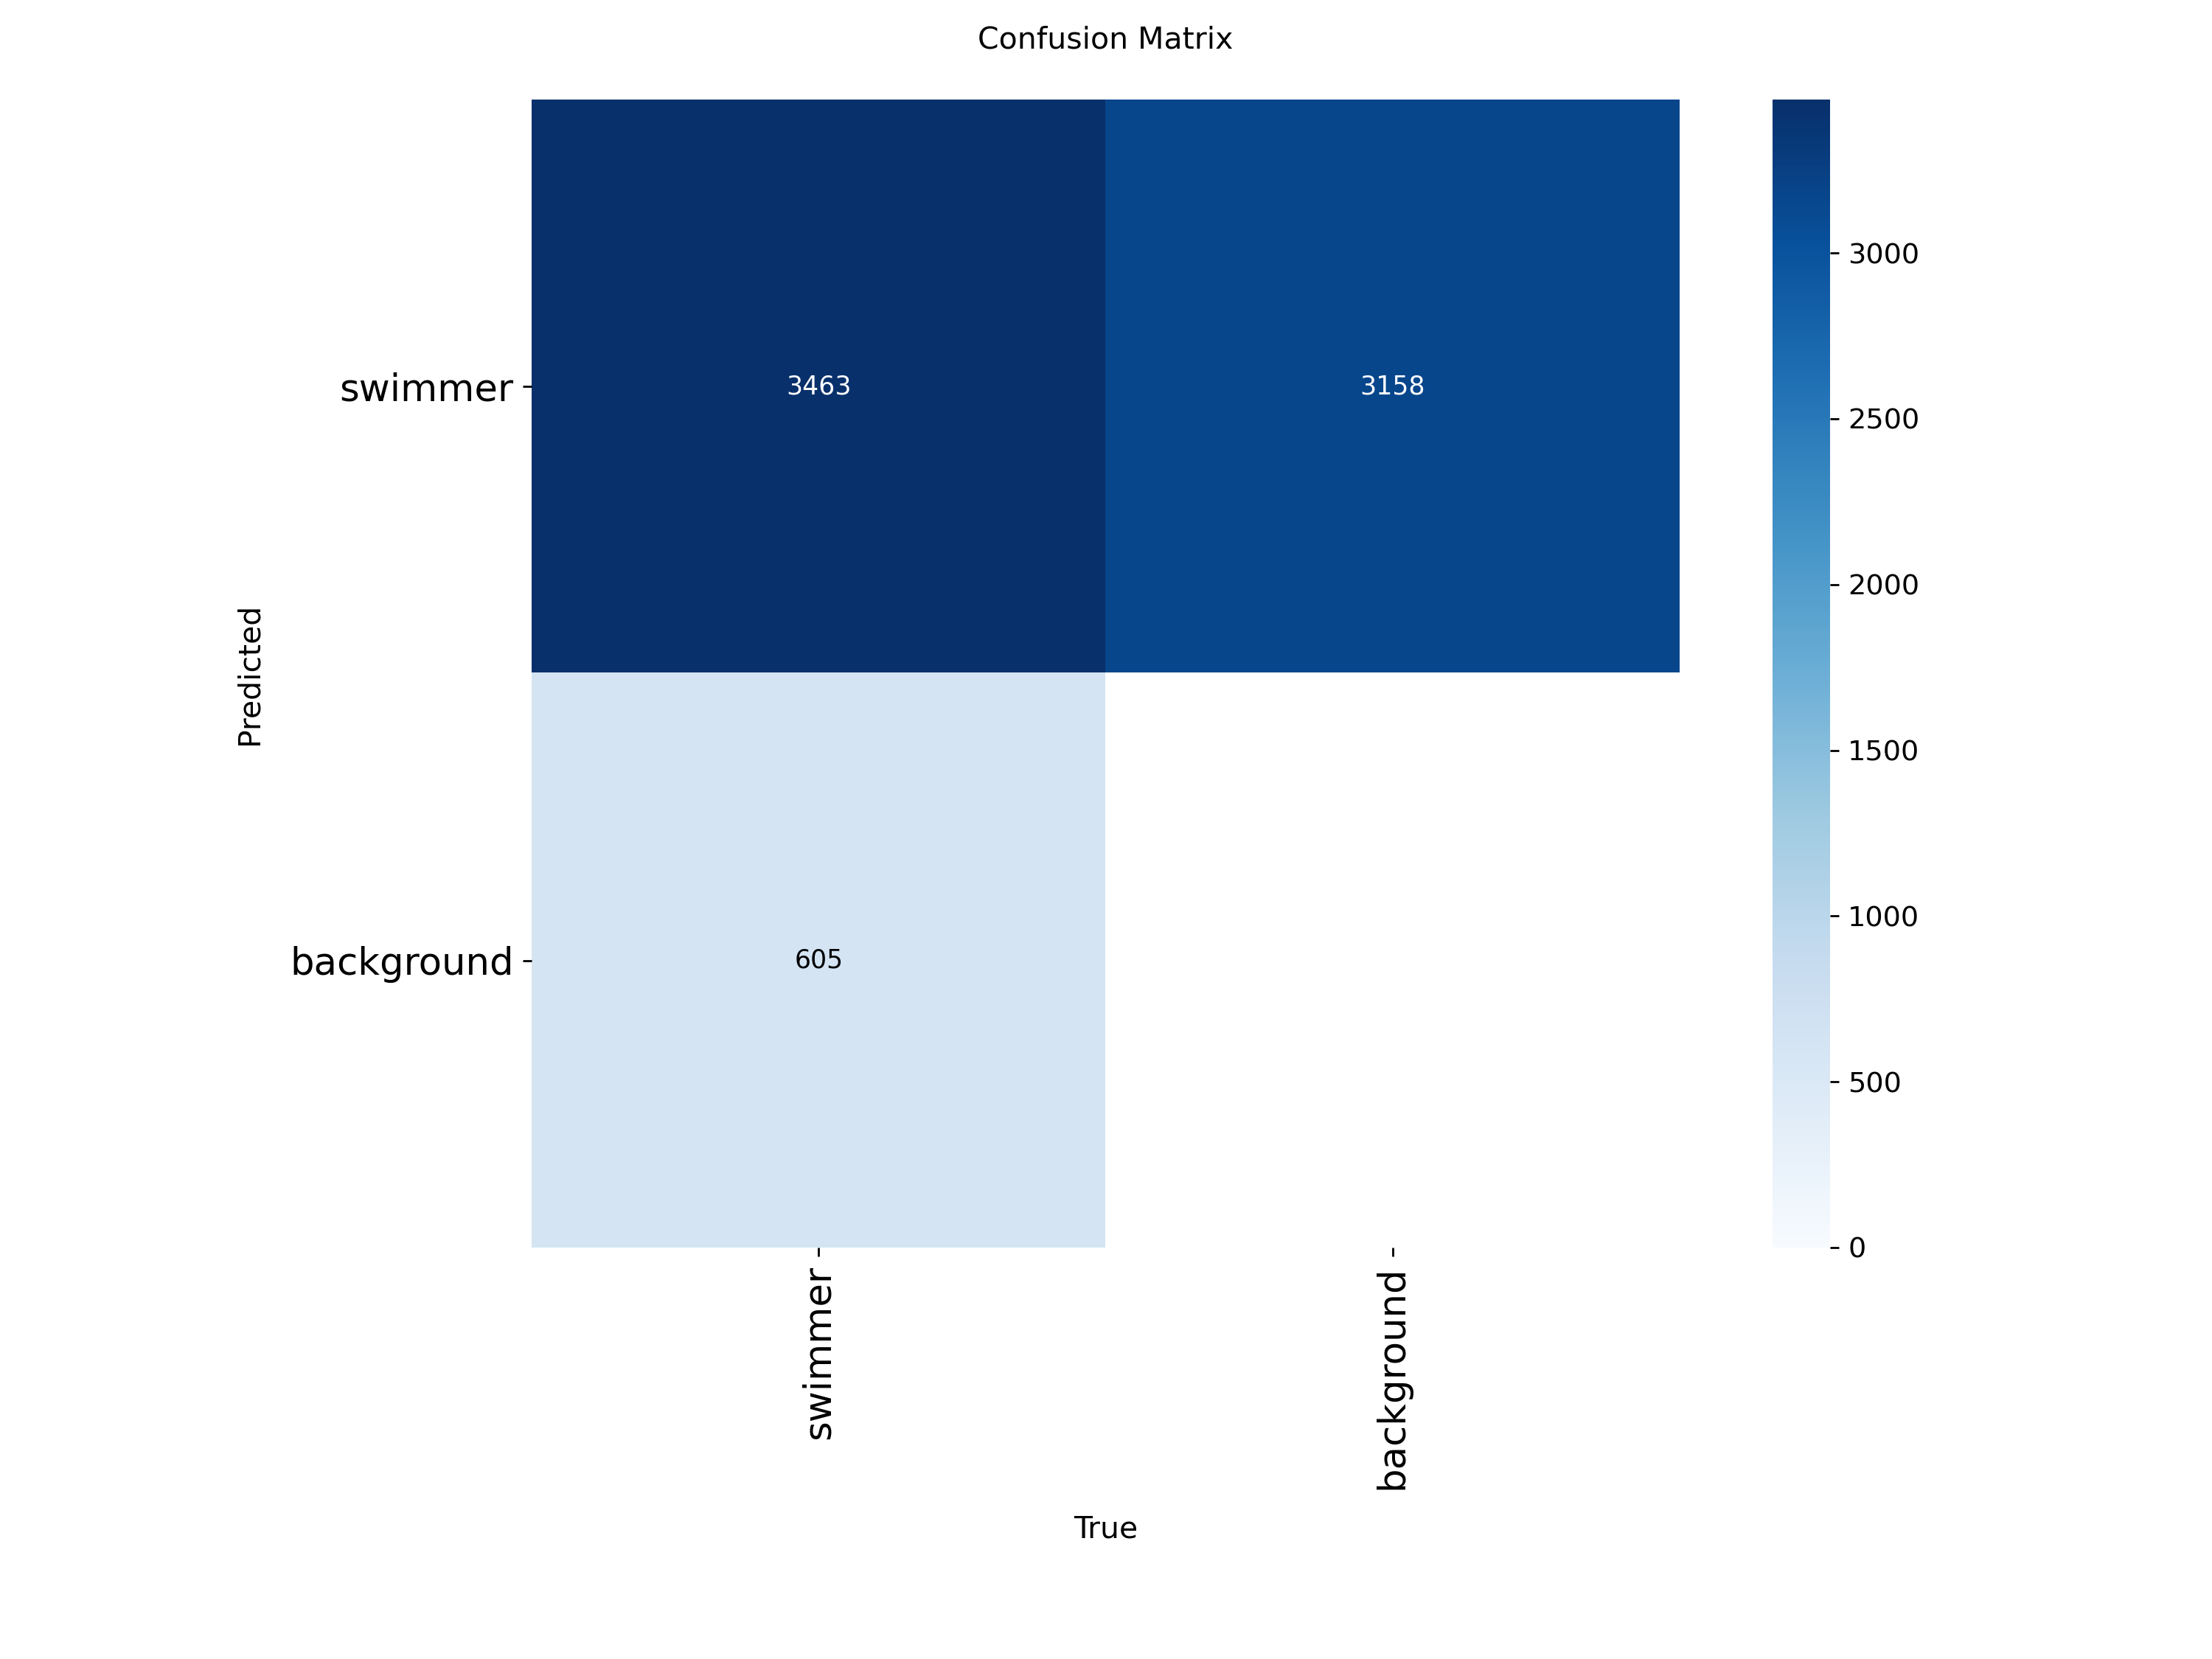

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3858.7±728.2 MB/s, size: 1007.3 KB)
val: Scanning /content/sds_swimmer/val/labels.cache... 1000 images, 160 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 155.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 3.0it/s 42.2s
                   all       1000       4068      0.835      0.799      0.765      0.326
Speed: 1.6ms preprocess, 9.4ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs/detect/val-12
Threshold: 0.1
Precision: 0.8348595903250327
Recall: 0.799410029498525
mAP50: 0.7647577996930566
mAP50-95: 0.3256319678943264


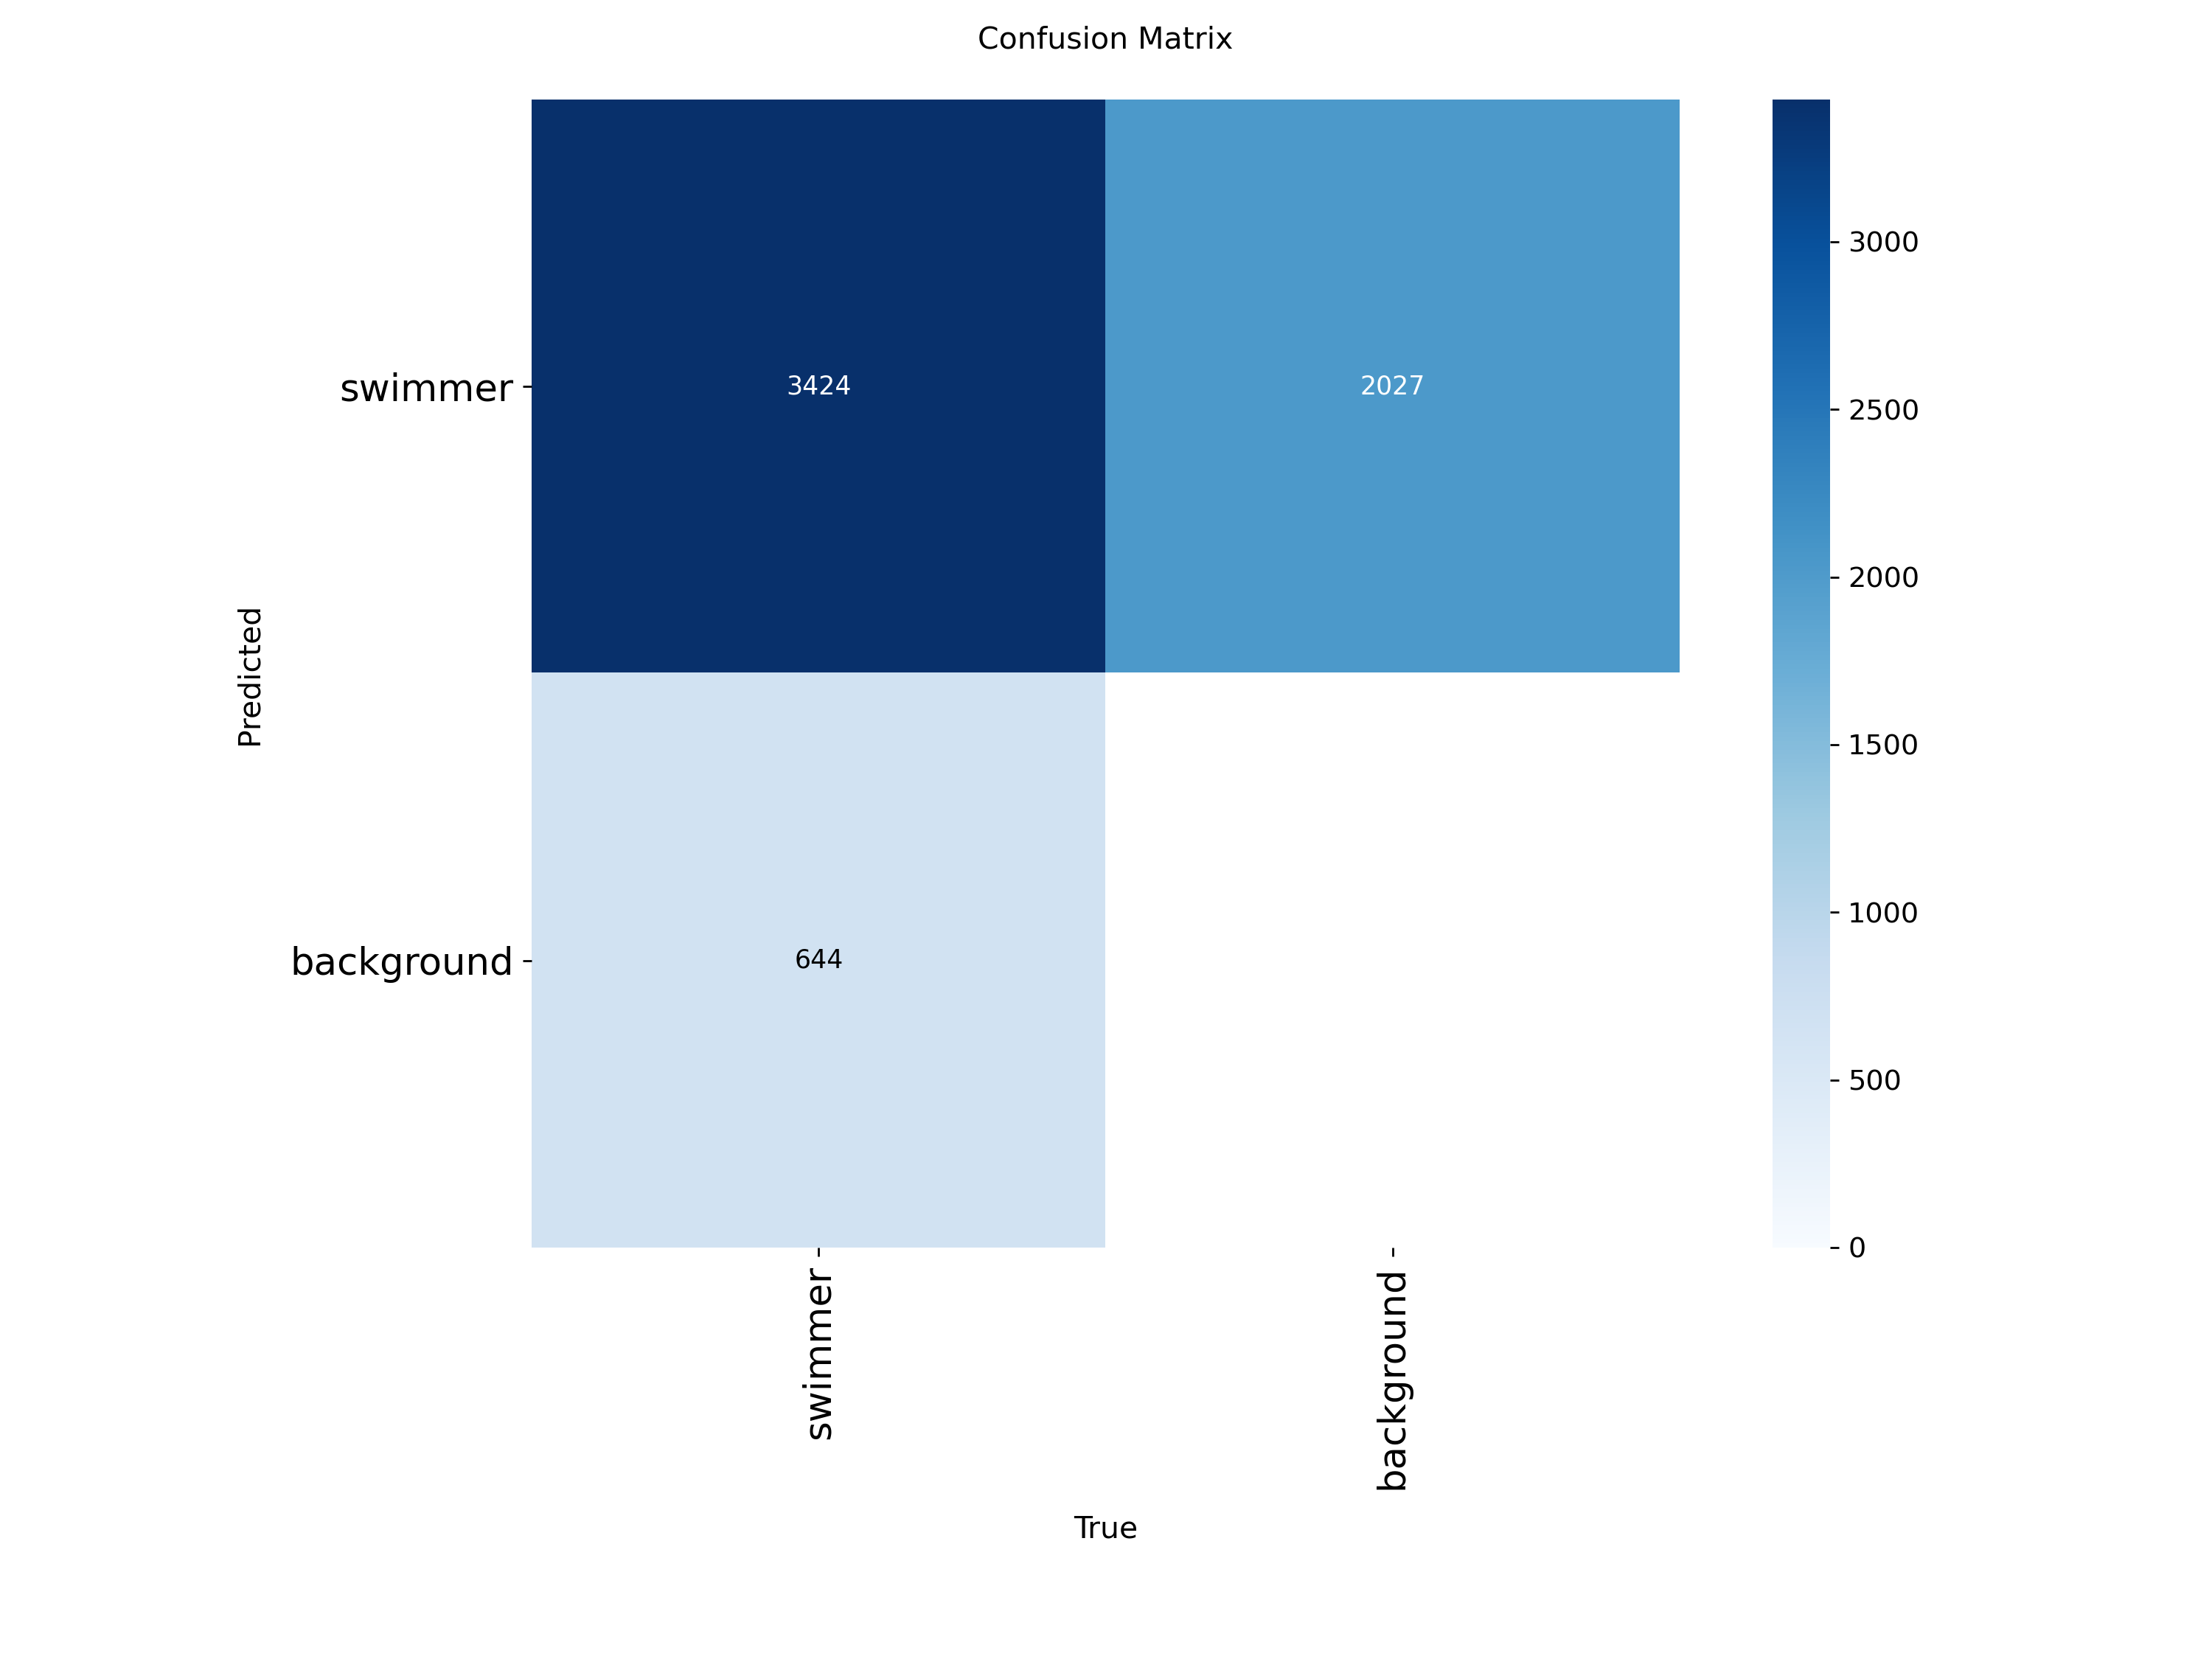

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3190.1±855.3 MB/s, size: 703.7 KB)
val: Scanning /content/sds_swimmer/val/labels.cache... 1000 images, 160 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 190.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 3.0it/s 41.9s
                   all       1000       4068      0.835      0.799      0.758      0.323
Speed: 1.7ms preprocess, 9.1ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs/detect/val-13
Threshold: 0.15
Precision: 0.8348595903250327
Recall: 0.799410029498525
mAP50: 0.7584117172571117
mAP50-95: 0.3228929758456181


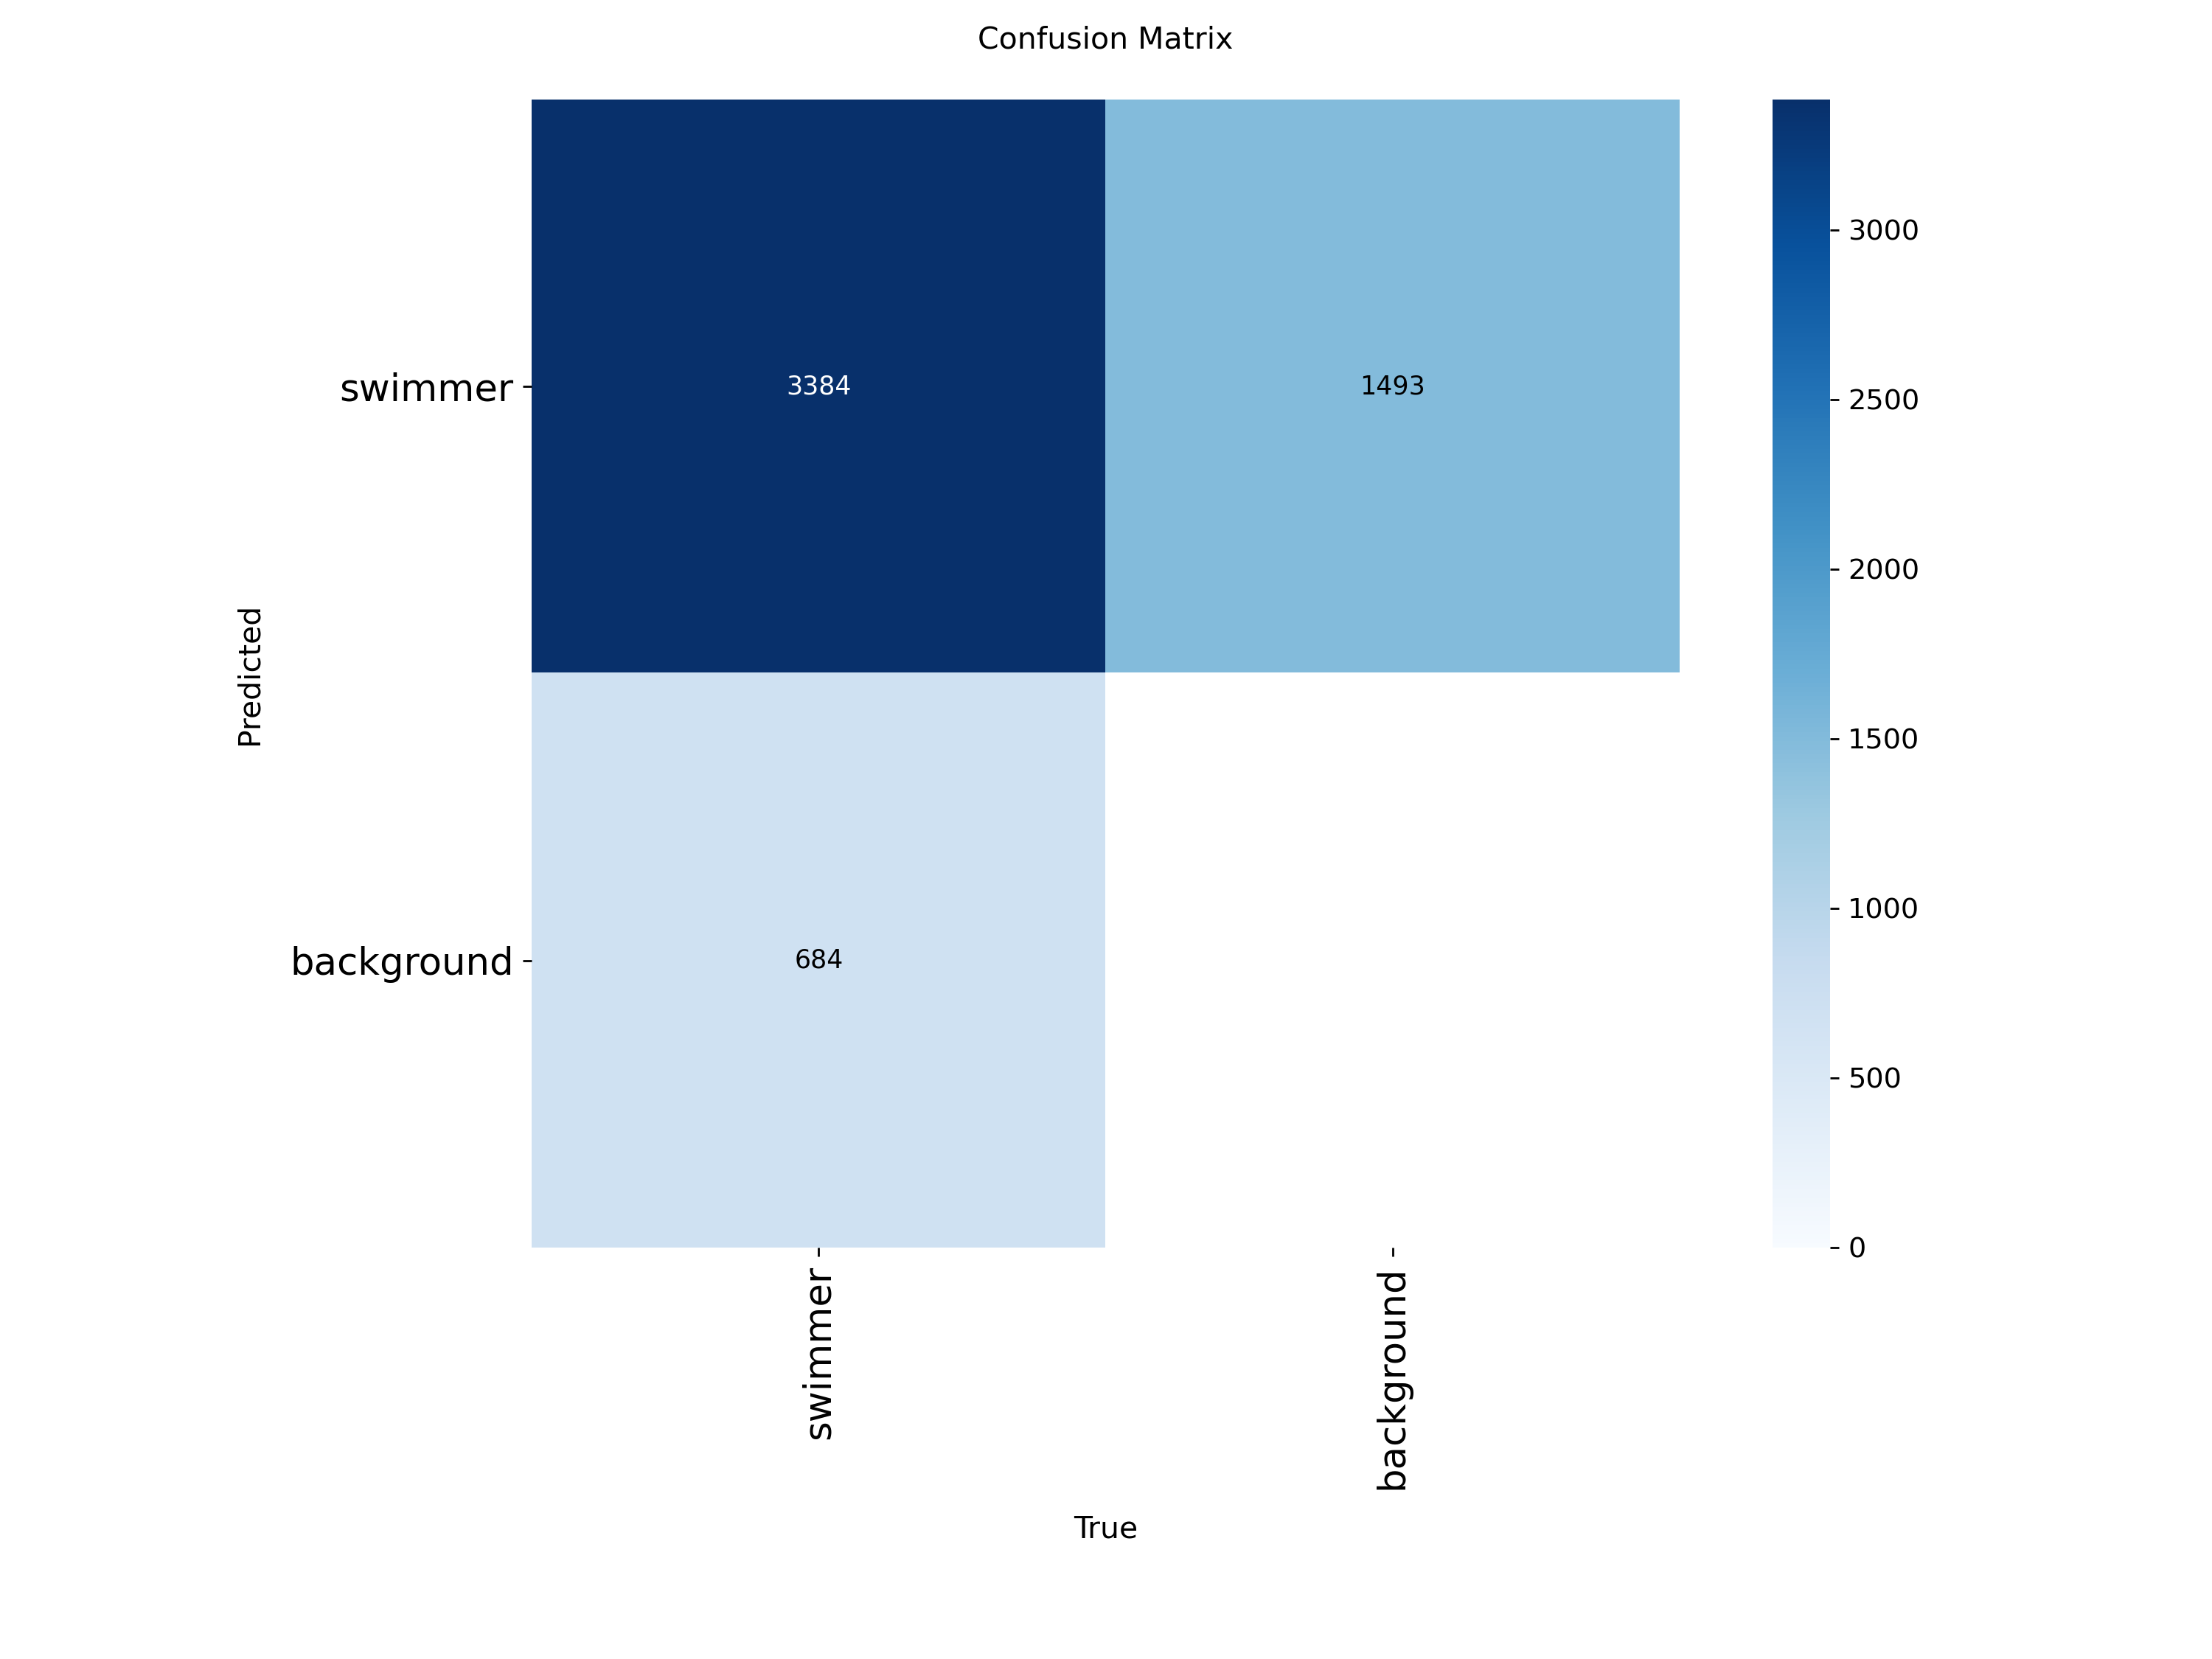

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3949.4±1260.7 MB/s, size: 948.7 KB)
val: Scanning /content/sds_swimmer/val/labels.cache... 1000 images, 160 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 299.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 3.0it/s 42.1s
                   all       1000       4068      0.835      0.799      0.751      0.319
Speed: 1.6ms preprocess, 9.3ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs/detect/val-14
Threshold: 0.25
Precision: 0.8348595903250327
Recall: 0.799410029498525
mAP50: 0.7513216479730469
mAP50-95: 0.31932059395745305


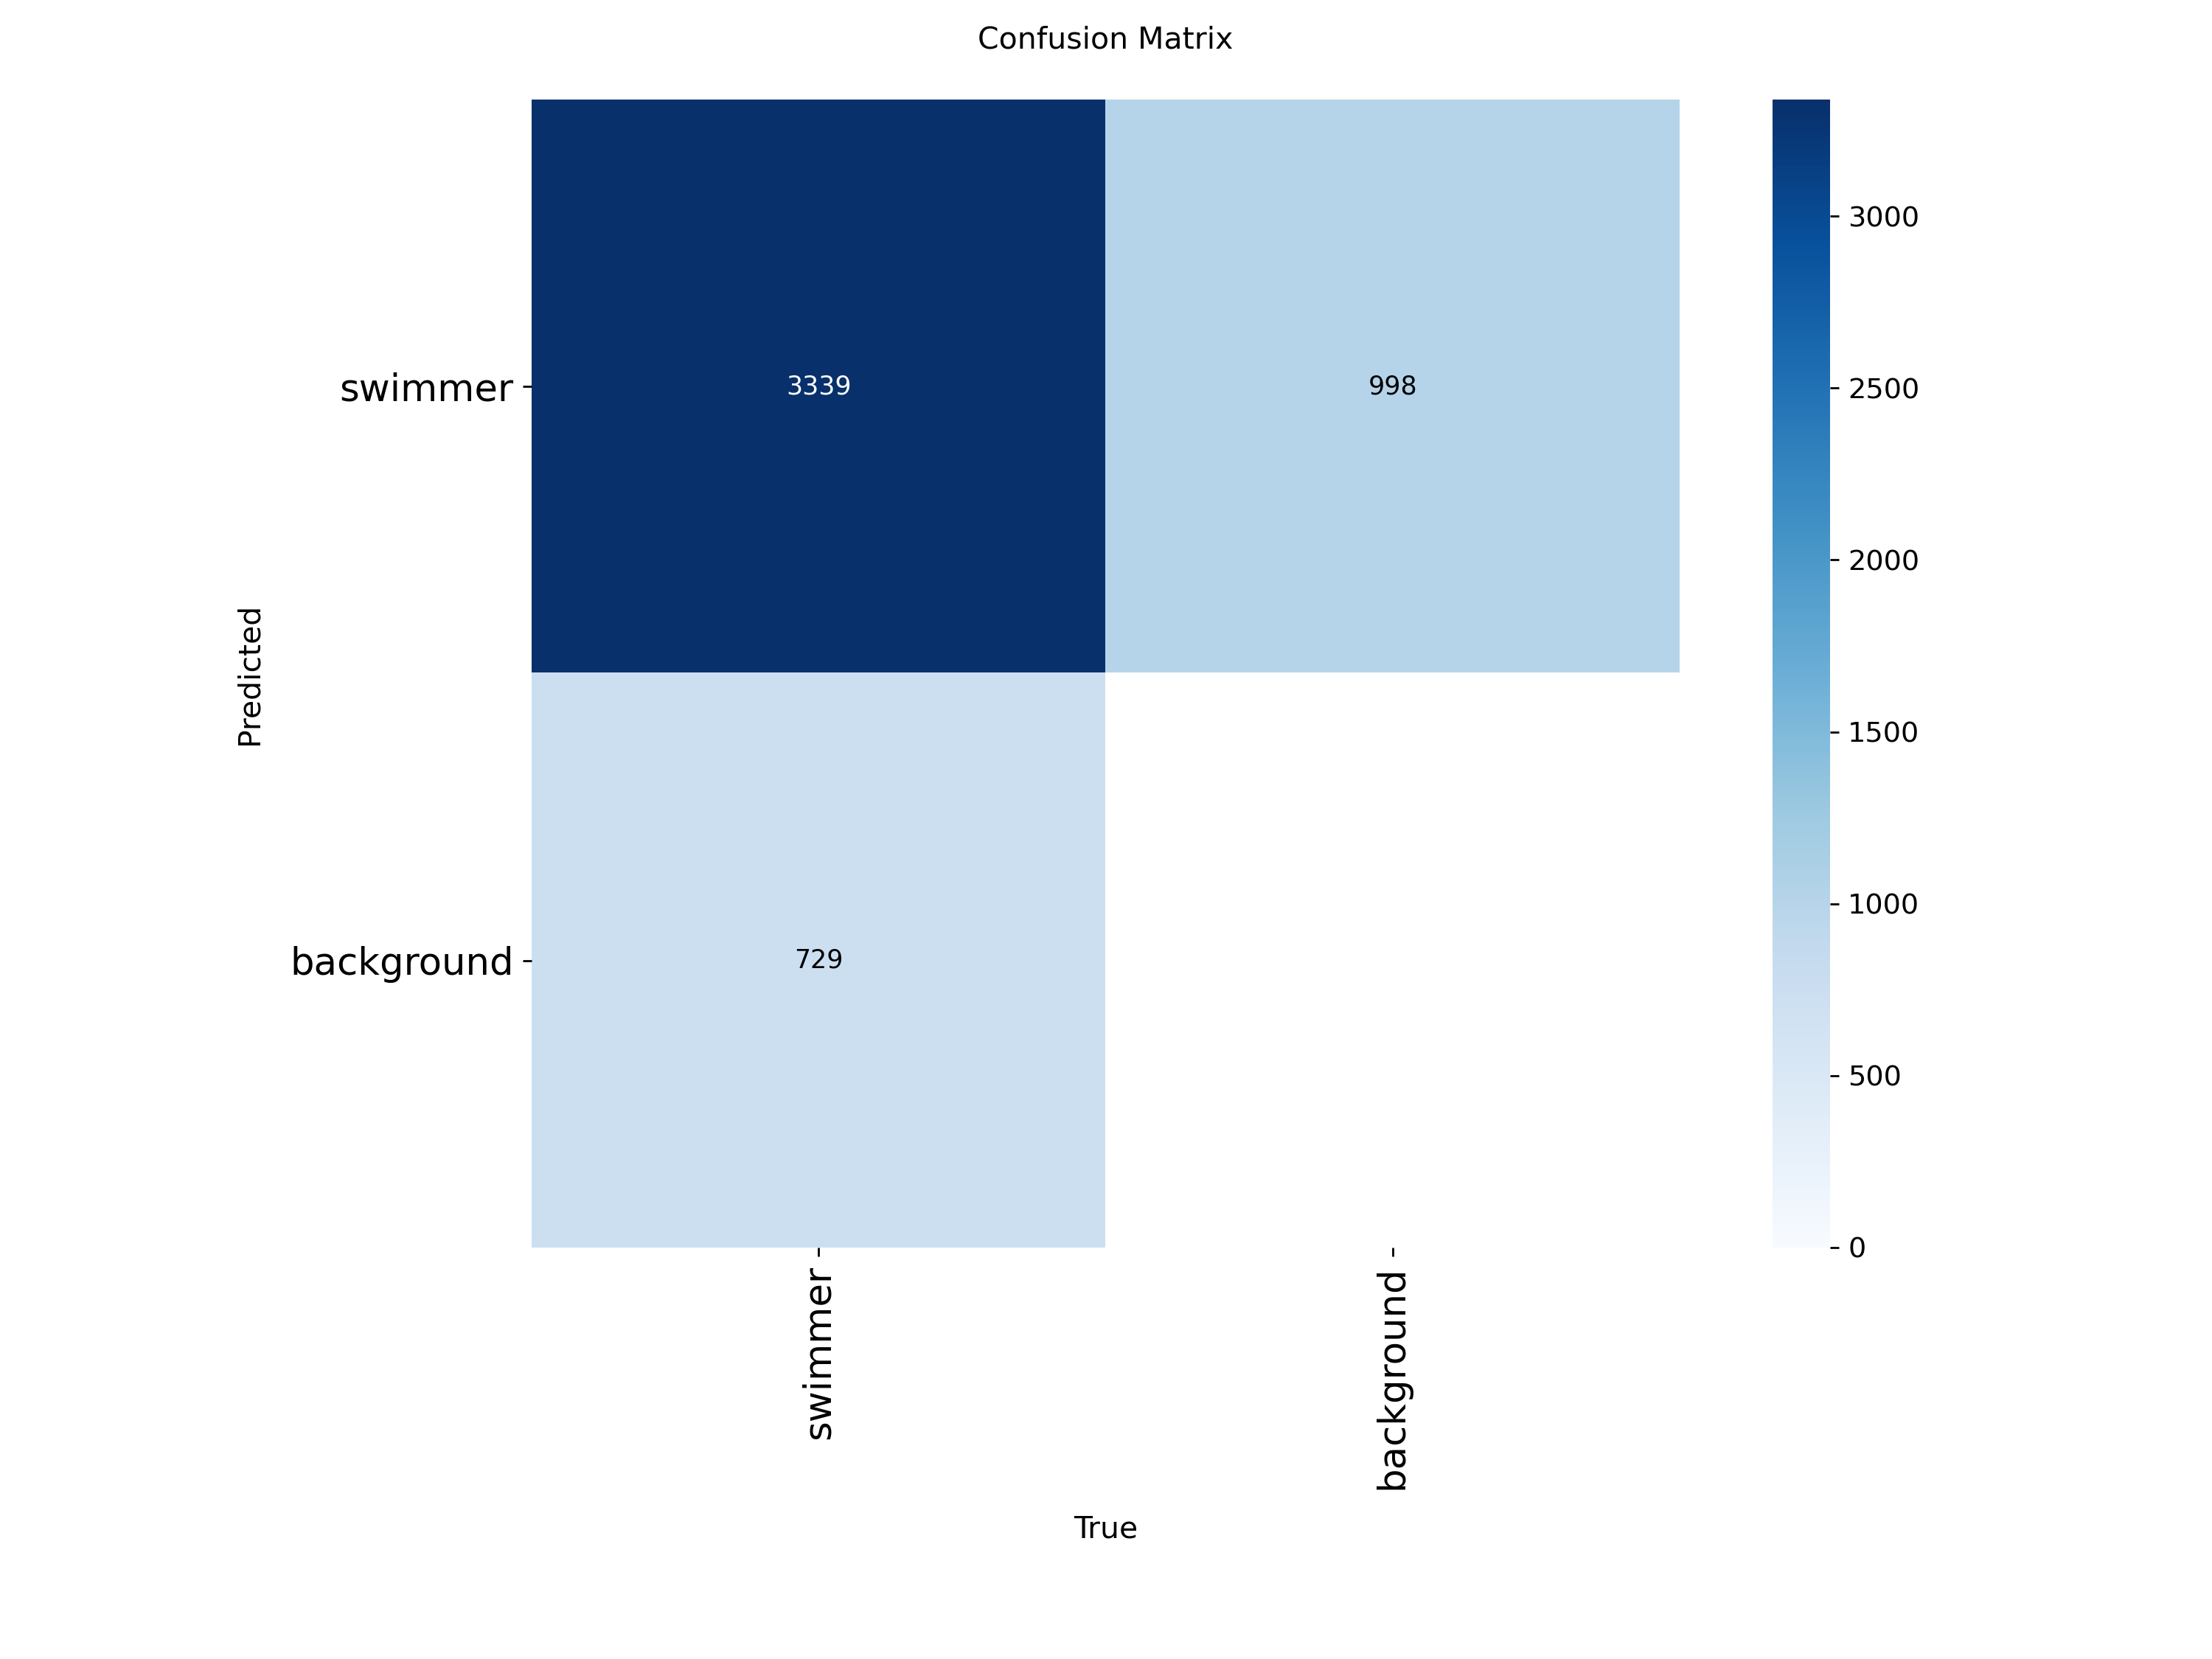

In [ ]:
threshold = [0.05, 0.1, 0.15, 0.25]

for i in threshold:
  model = YOLO('/content/model1.pt')
  metrics = model.val(
    data = '/content/sds_swimmer/data.yaml',
    split='val',
    imgsz = 800,
    batch=8,
    conf = i,
    verbose = True
  )
  print(f"Threshold: {i}")
  display(Image(filename=str(metrics.save_dir / 'confusion_matrix.png')))




Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2682.7±1163.6 MB/s, size: 359.8 KB)
val: Scanning /content/sds_swimmer/val/labels.cache... 1000 images, 160 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 199.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 3.0it/s 42.2s
                   all       1000       4068      0.859      0.831      0.807      0.352
Speed: 1.6ms preprocess, 9.6ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs/detect/val-15
Threshold: 0.05


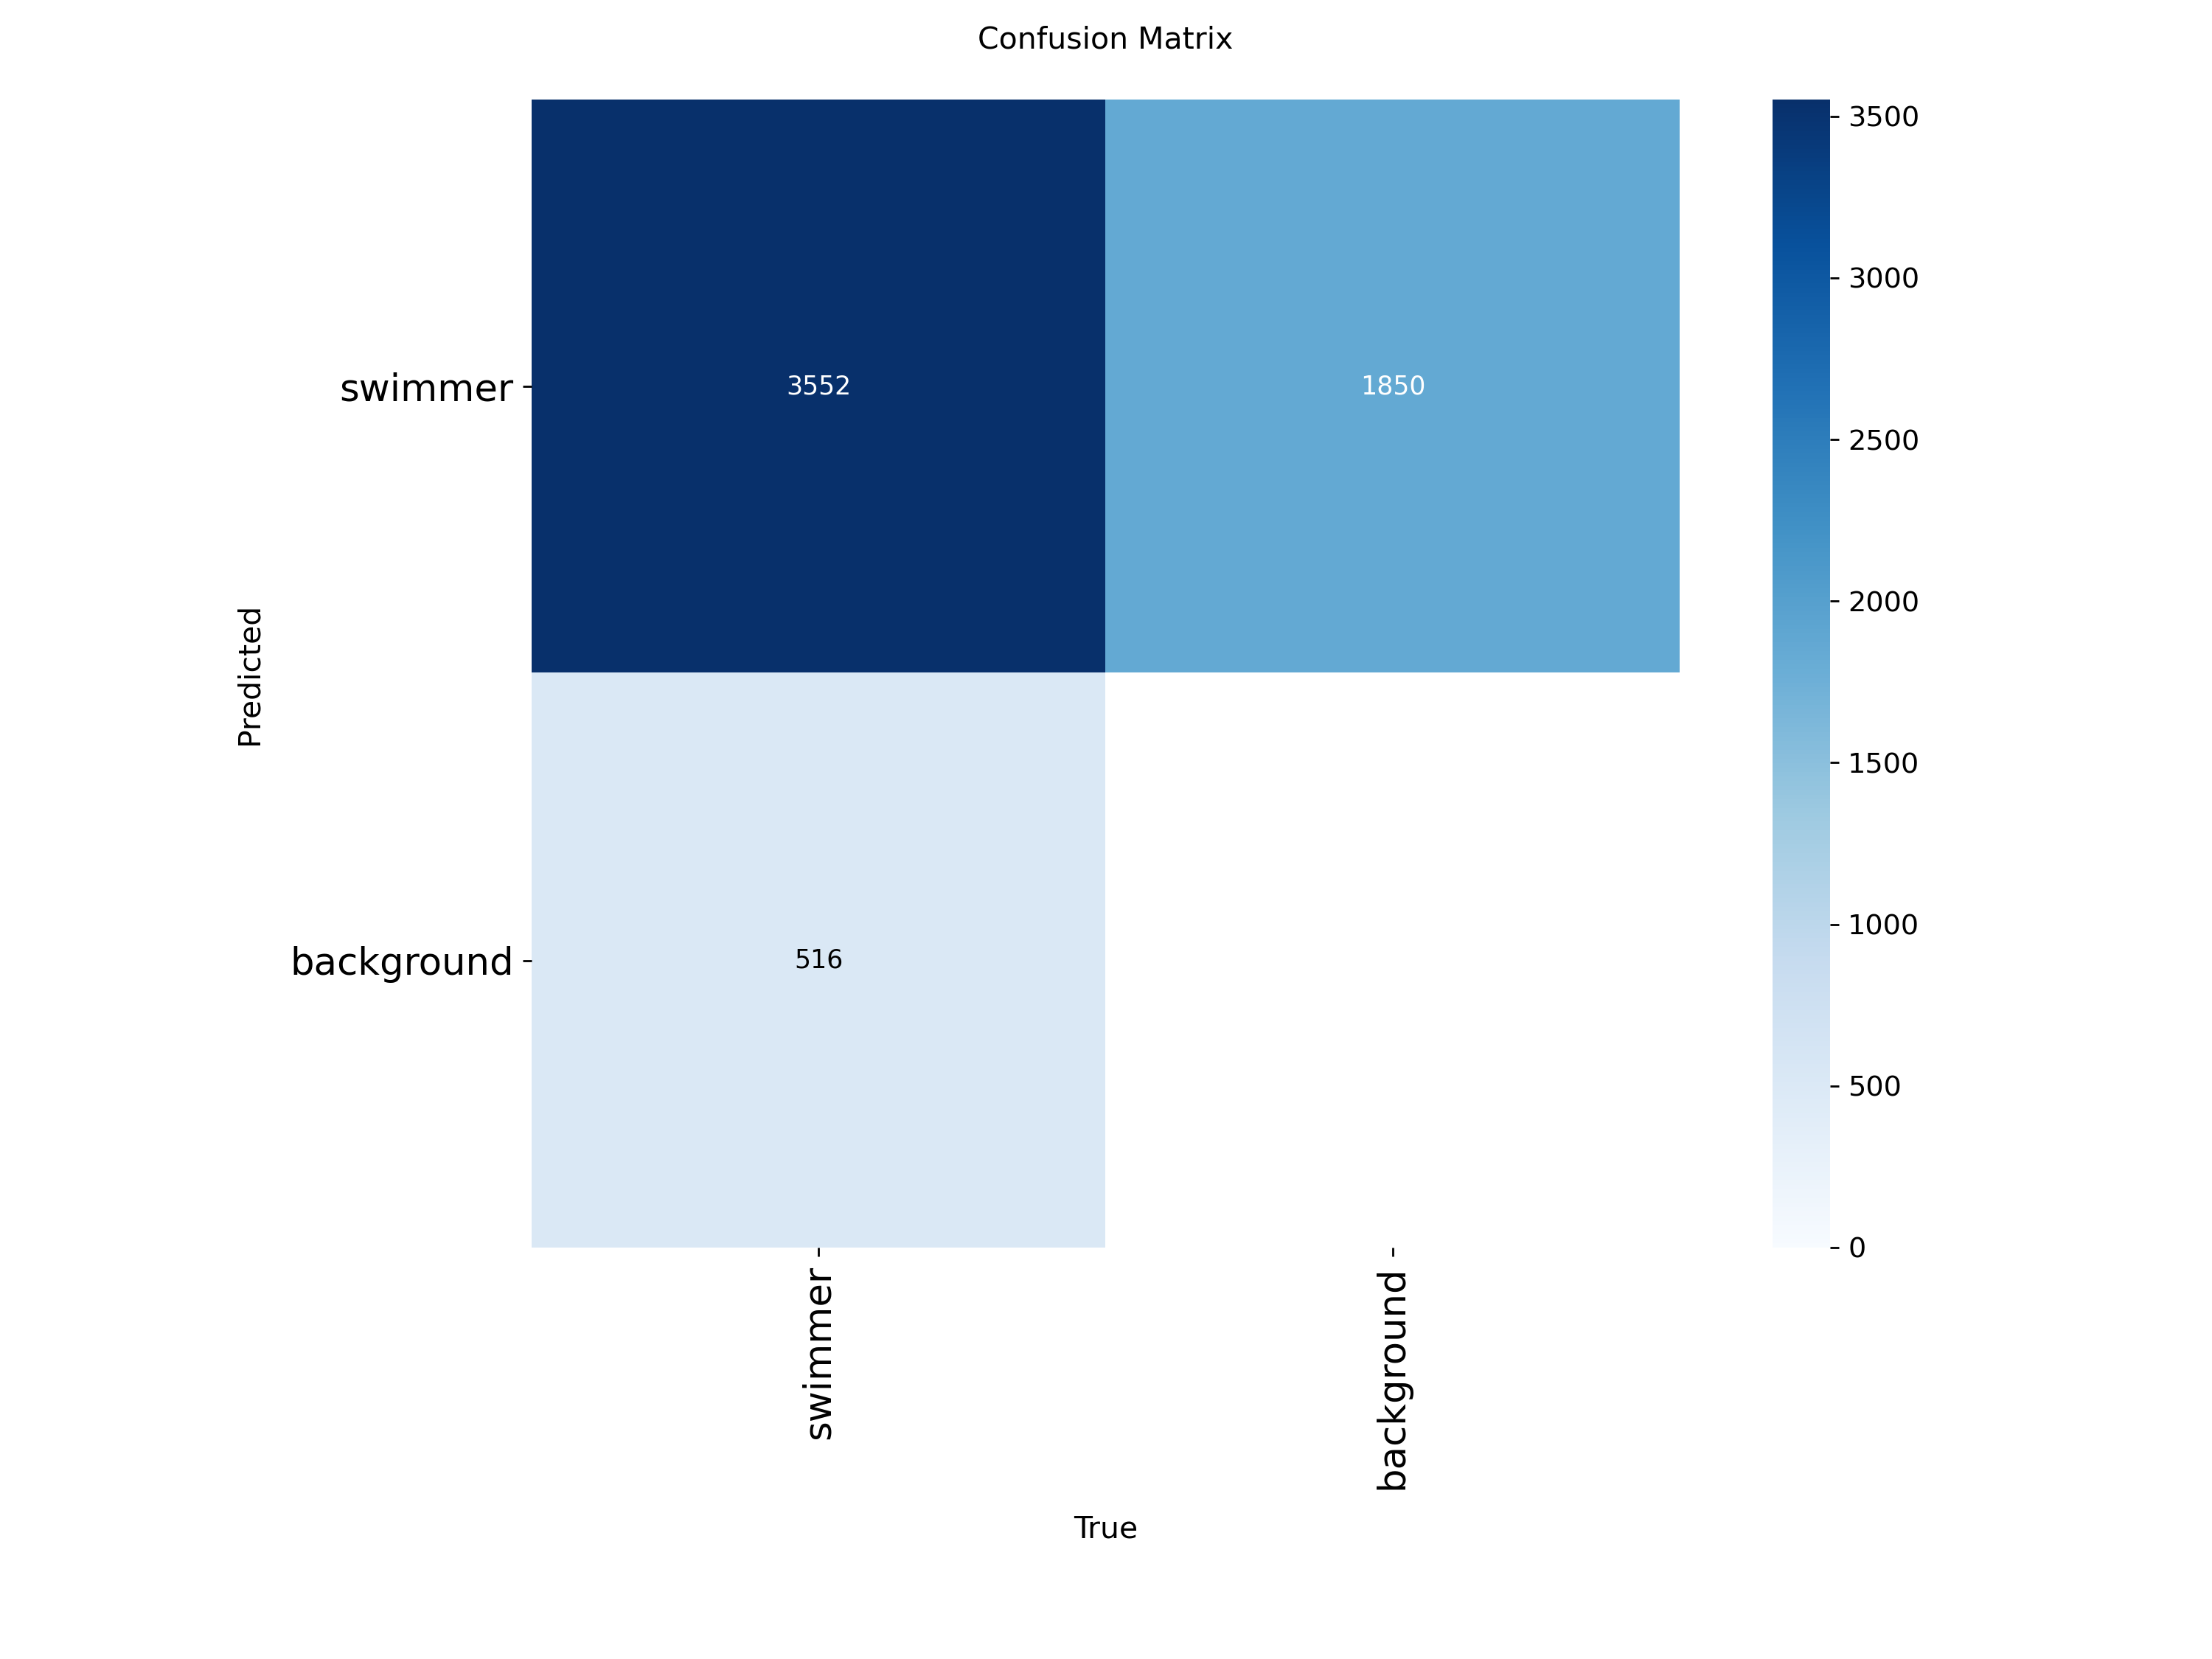

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3226.8±1407.8 MB/s, size: 680.5 KB)
val: Scanning /content/sds_swimmer/val/labels.cache... 1000 images, 160 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 209.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 3.0it/s 41.8s
                   all       1000       4068      0.859      0.831        0.8      0.349
Speed: 1.7ms preprocess, 9.3ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/runs/detect/val-16
Threshold: 0.1


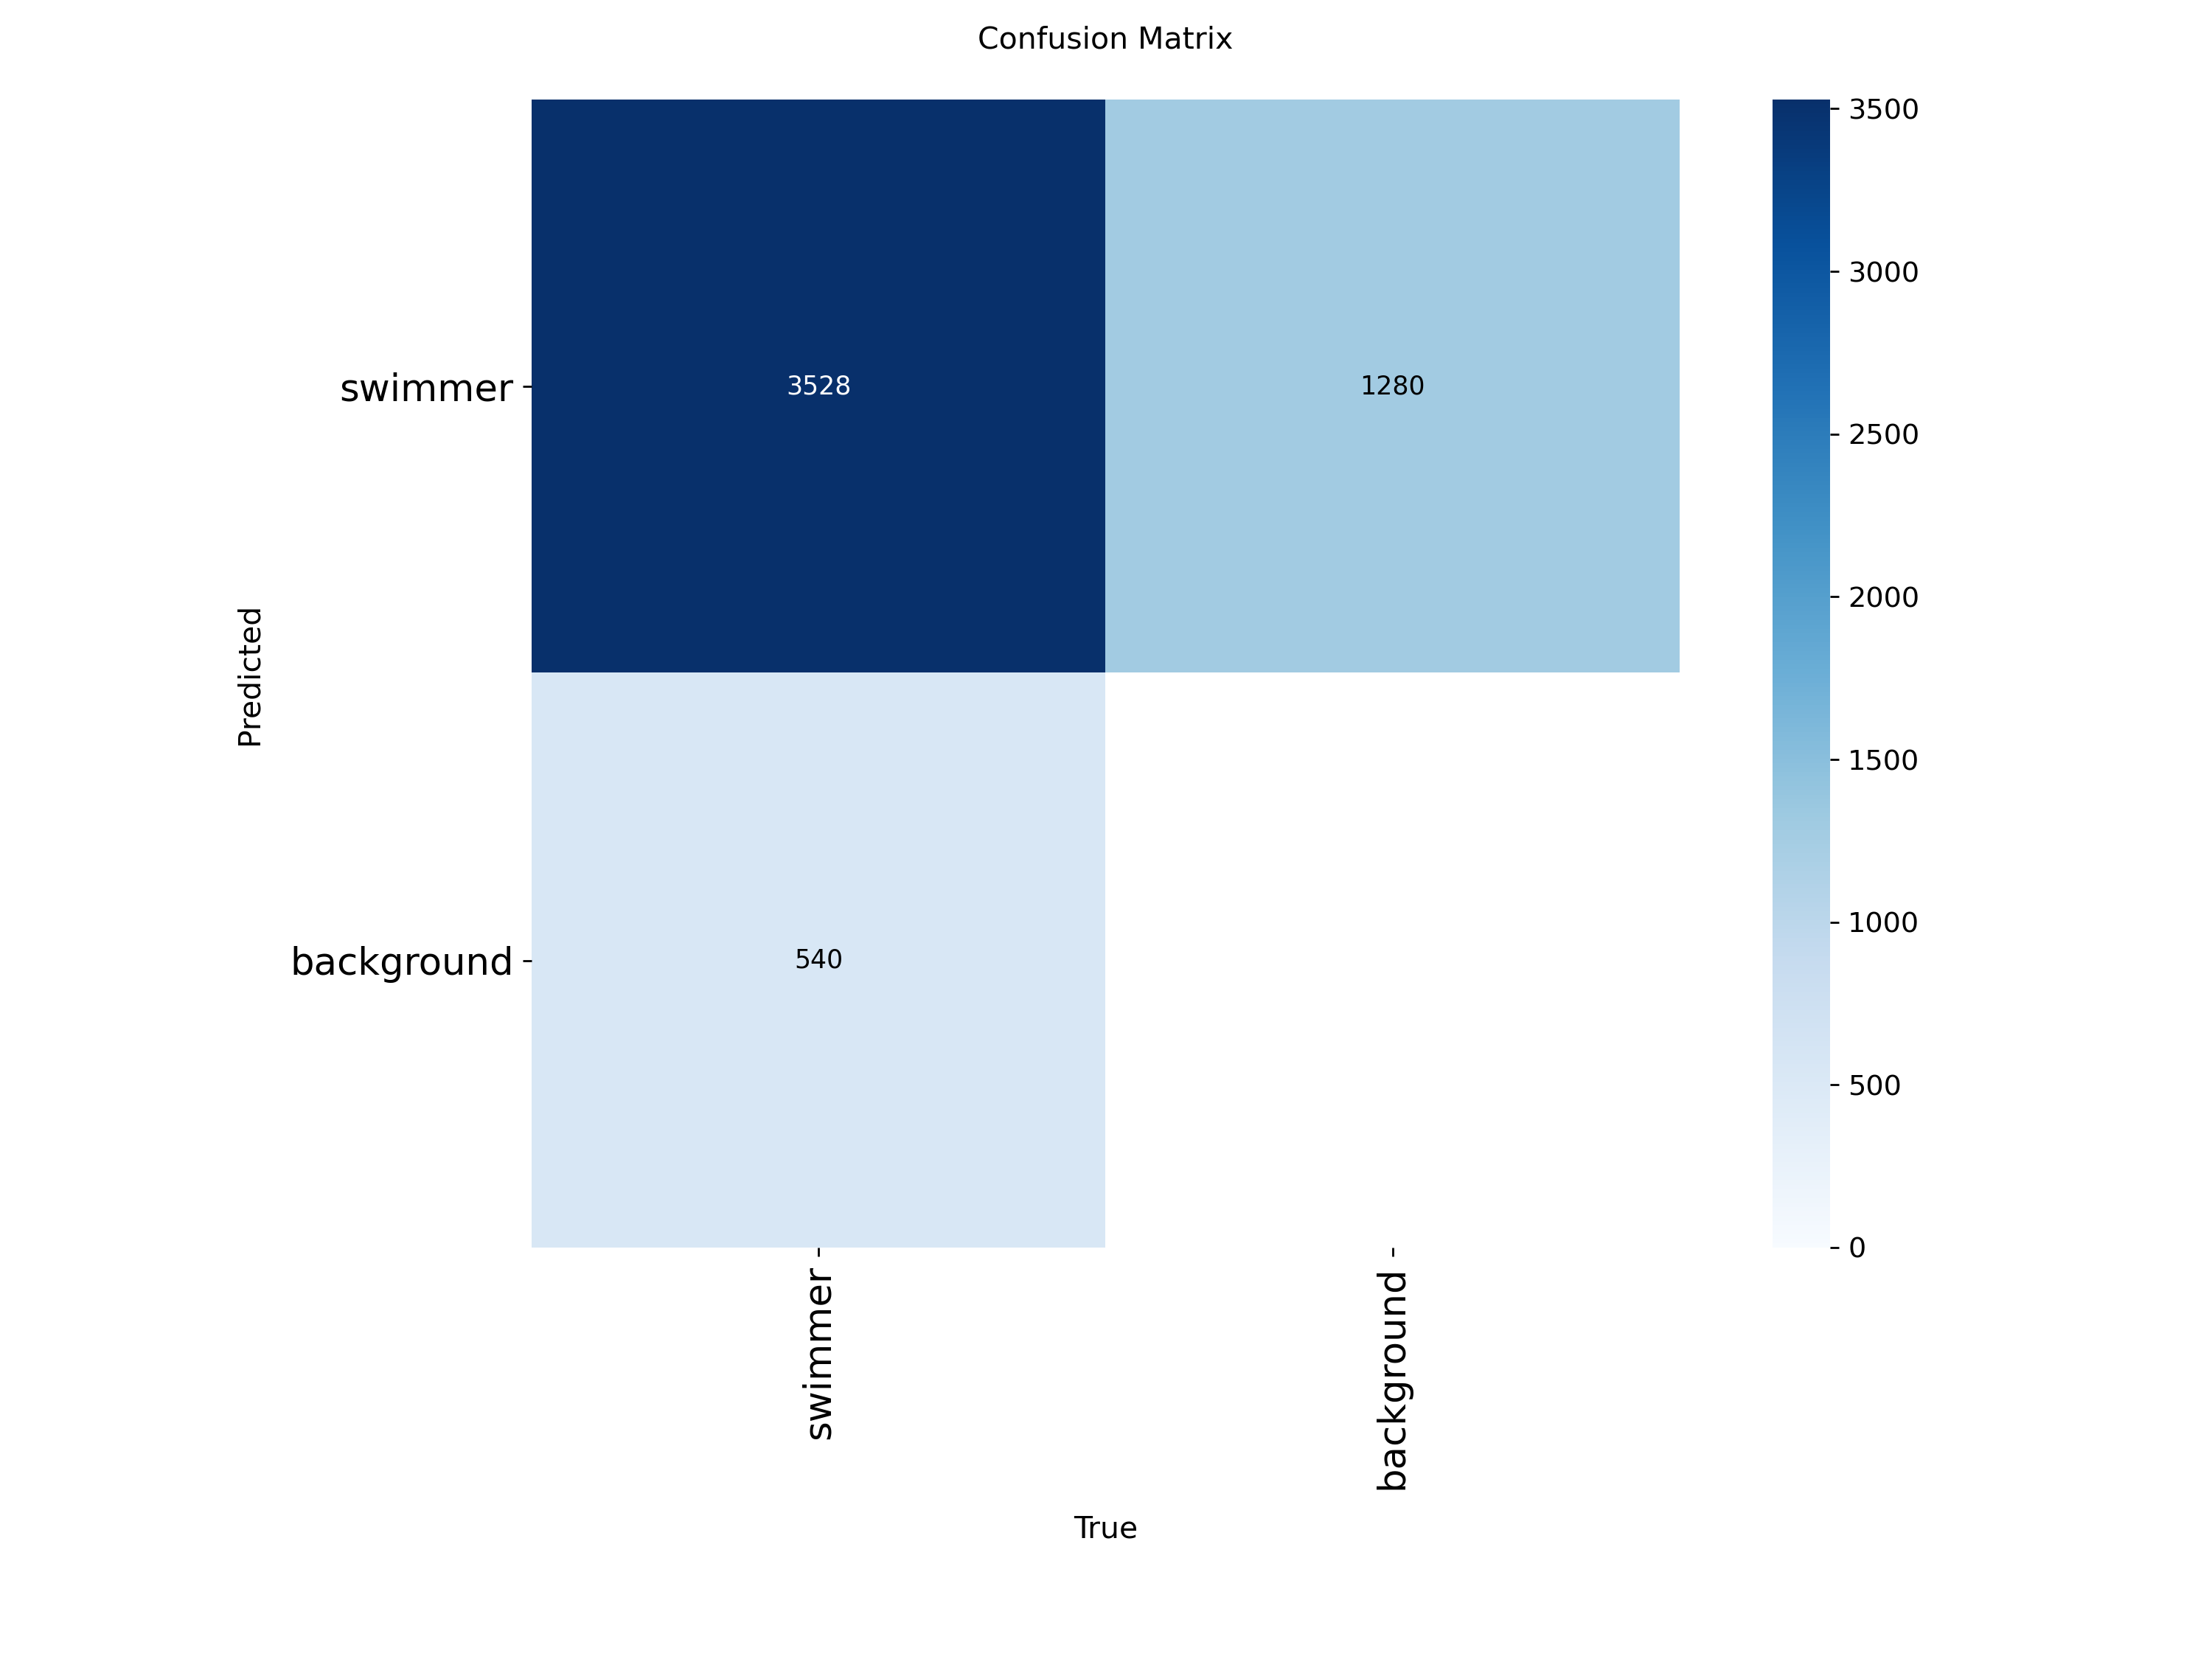

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4599.7±813.0 MB/s, size: 991.8 KB)
val: Scanning /content/sds_swimmer/val/labels.cache... 1000 images, 160 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 199.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 3.0it/s 42.0s
                   all       1000       4068      0.859      0.831        0.8      0.349
Speed: 1.6ms preprocess, 9.3ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs/detect/val-17
Threshold: 0.15


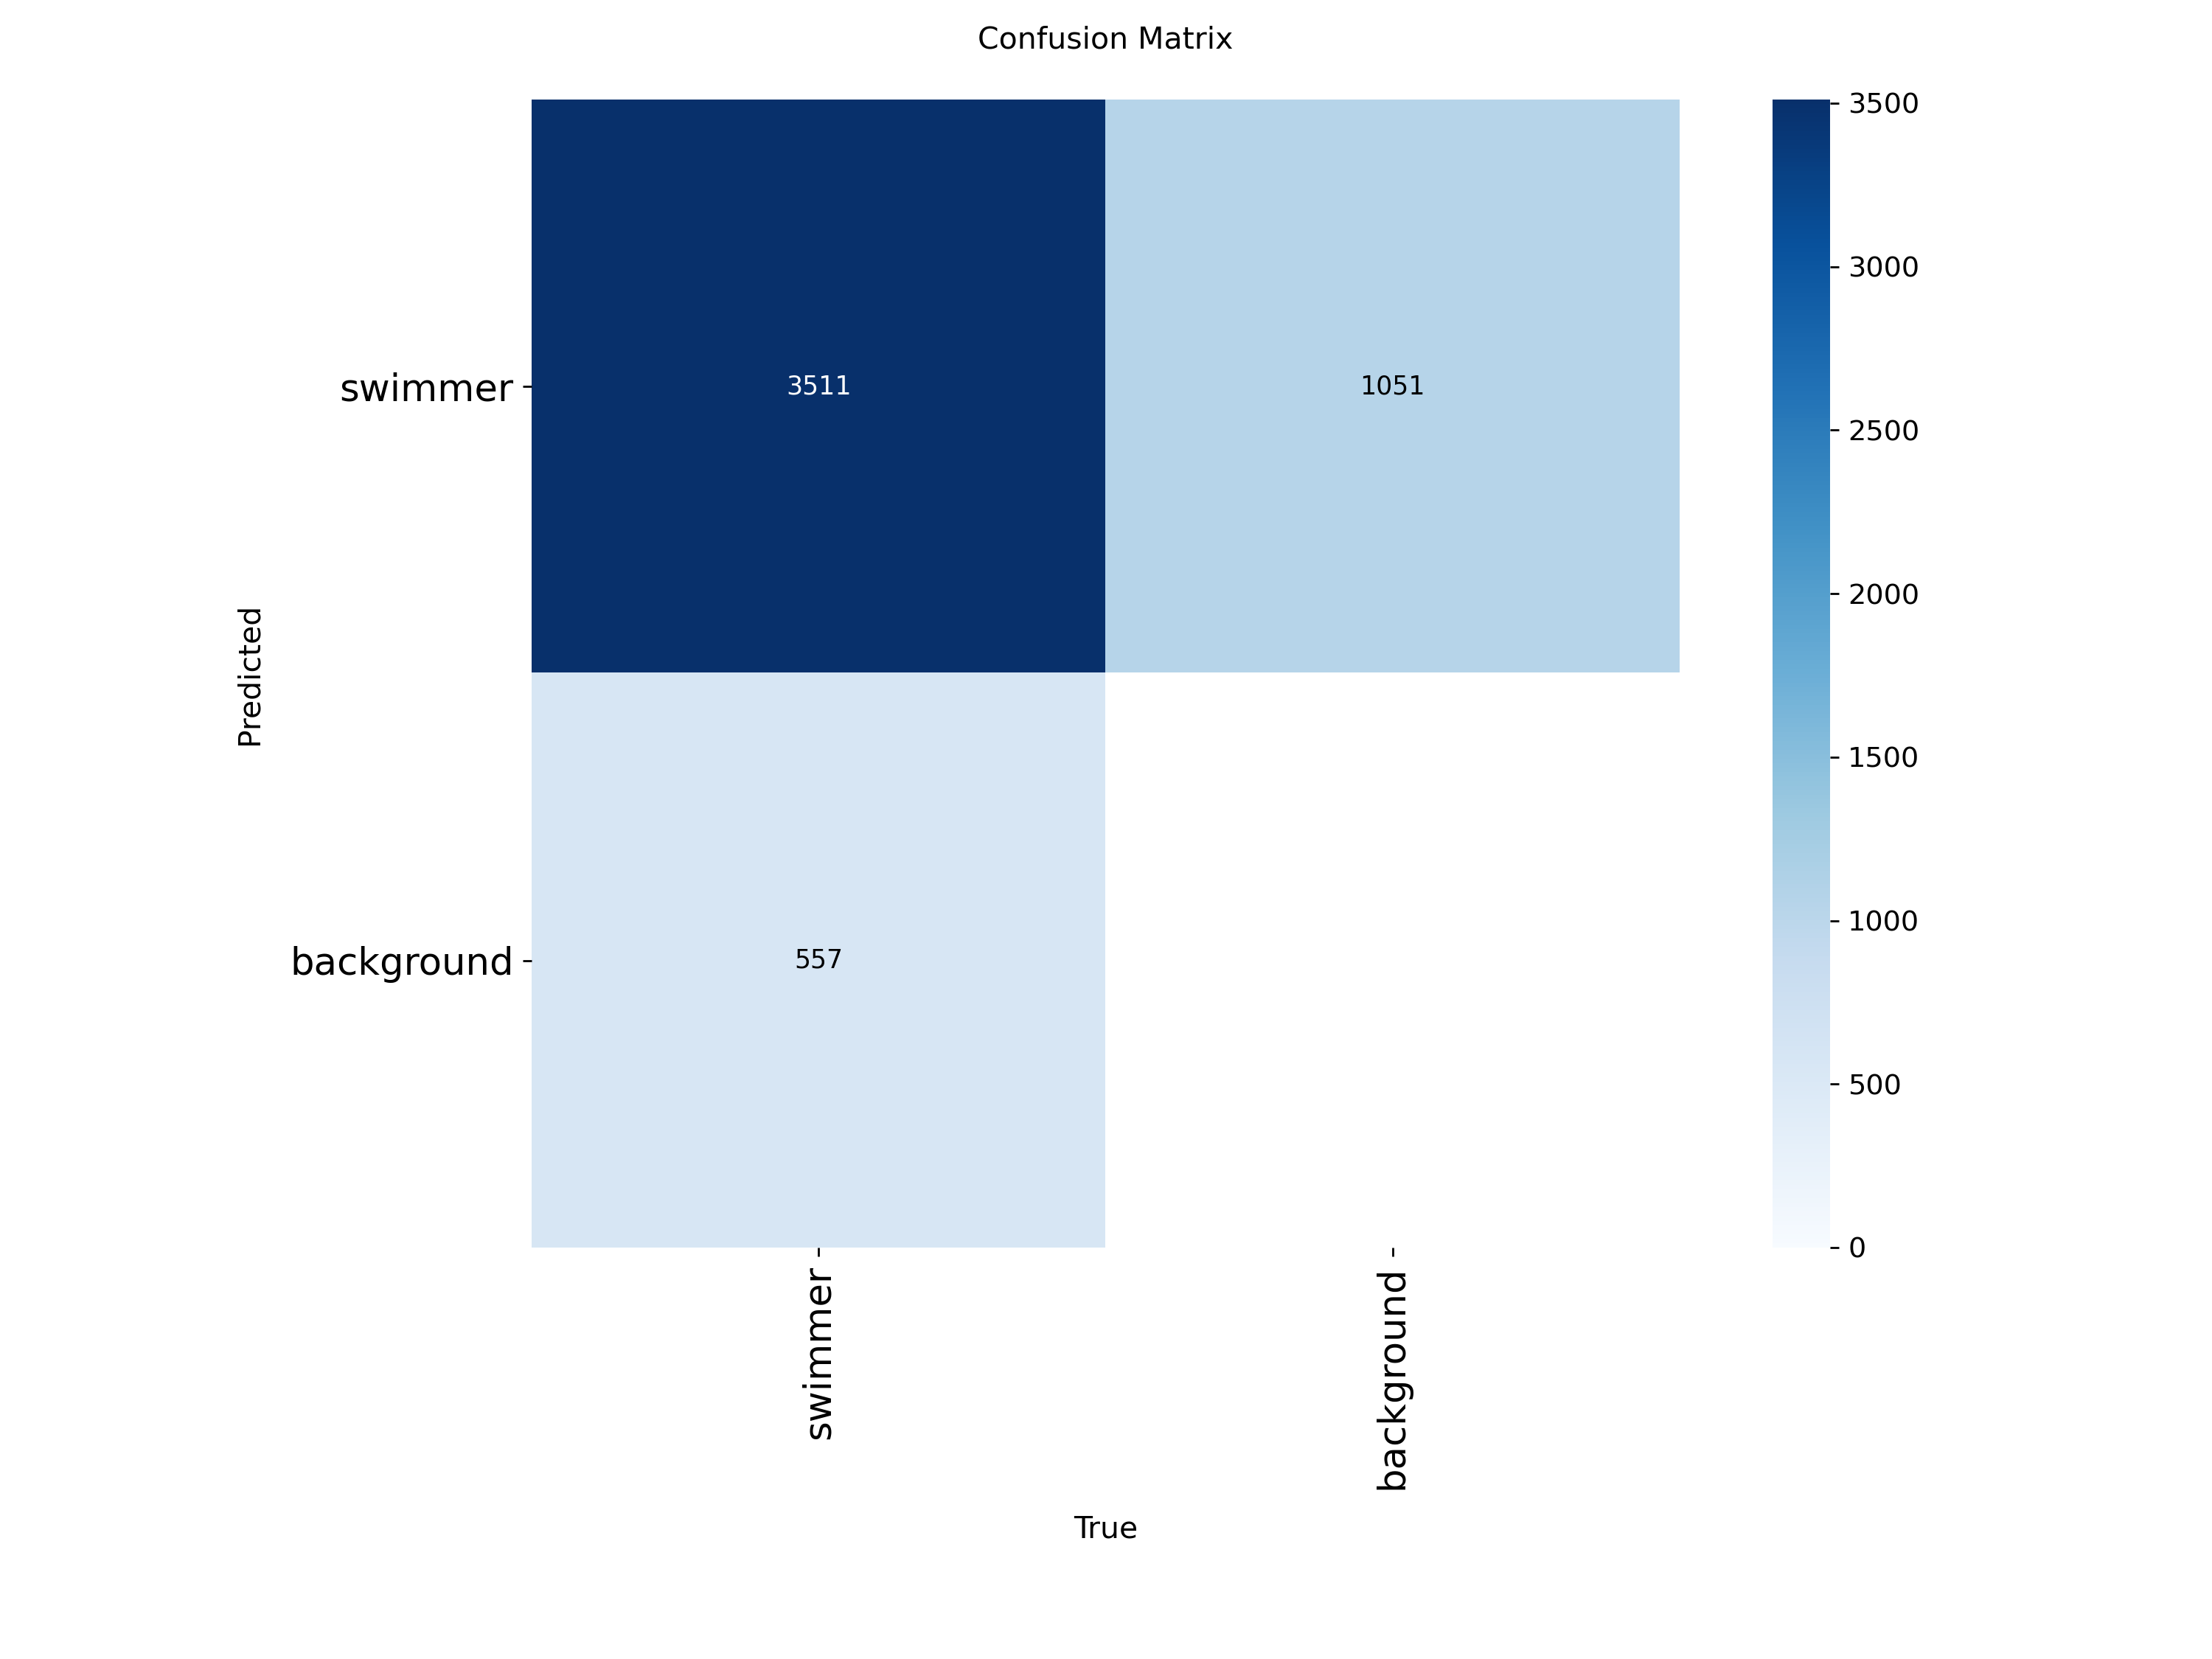

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2764.4±1161.4 MB/s, size: 853.6 KB)
val: Scanning /content/sds_swimmer/val/labels.cache... 1000 images, 160 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 199.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 2.9it/s 42.8s
                   all       1000       4068      0.859      0.831      0.792      0.345
Speed: 1.7ms preprocess, 9.1ms inference, 0.0ms loss, 1.8ms postprocess per image
Results saved to /content/runs/detect/val-18
Threshold: 0.25


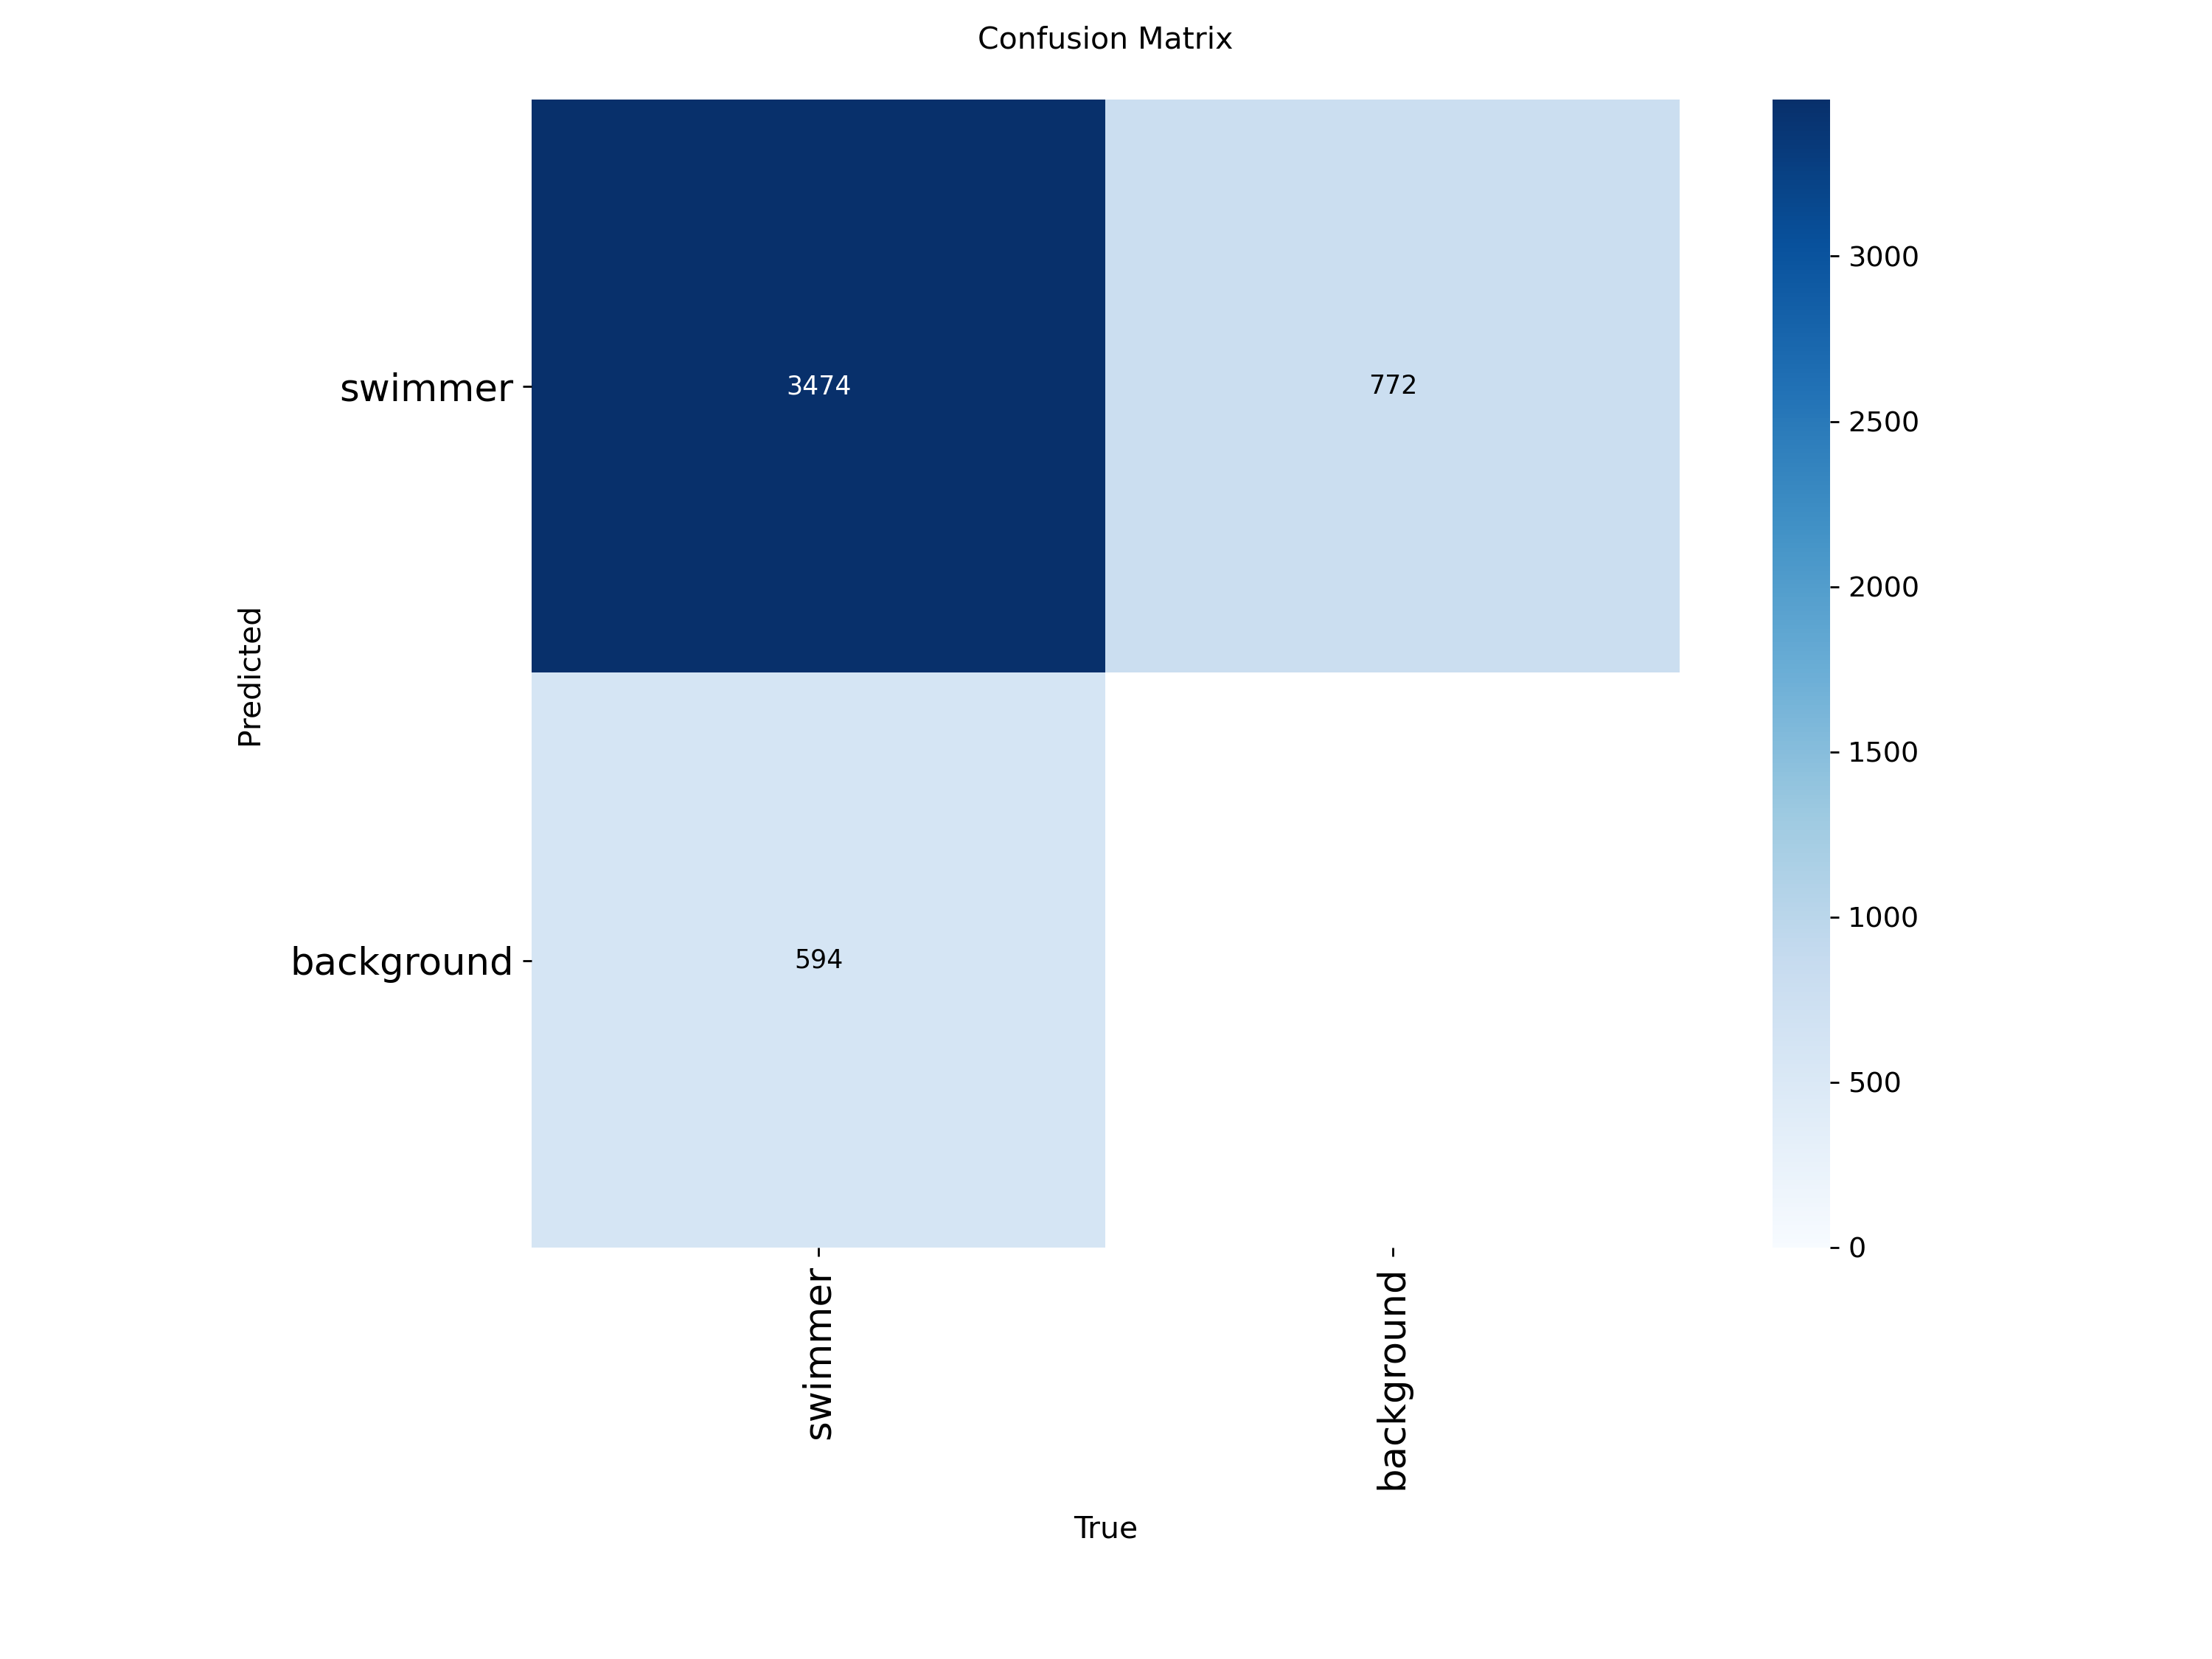

In [ ]:
for i in threshold:
  model = YOLO('/content/yolo26s_final_best.pt')
  metrics = model.val(
    data = '/content/sds_swimmer/data.yaml',
    split='val',
    imgsz = 800,
    batch=8,
    conf = i,
    verbose = True
  )
  print(f"Threshold: {i}")
  display(Image(filename=str(metrics.save_dir / 'confusion_matrix.png')))

The best threshold for both models is 0.25.

#YOLOv11 Model Evaluation

In [ ]:
model = YOLO('/content/model1.pt')

In [ ]:
metrics = model.val(
    data = '/content/sds_swimmer/data.yaml',
    split='test',
    imgsz = 800,
    batch=8,
    conf = 0.25
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2602.4±629.1 MB/s, size: 482.7 KB)
val: Scanning /content/sds_swimmer/test/labels.cache... 1000 images, 225 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 199.7Mit/s 0.0s
val: /content/sds_swimmer/test/images/9568.jpg: 1 duplicate labels removed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 2.7it/s 46.4s
                   all       1000       4192        0.8      0.769      0.754      0.313
Speed: 1.7ms preprocess, 8.8ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/runs/detect/val-24


In [ ]:
print(f"Final Model Evaluation (YOLOv11)")
print(f"Precision: {metrics.box.mp:.2f}")
print(f"Recall: {metrics.box.mr:.2f}")
print(f"mAP50: {metrics.box.map50:.2f}")
print(f"mAP50-95: {metrics.box.map:.2f}")

Final Model Evaluation (YOLOv11)
Precision: 0.83
Recall: 0.80
mAP50: 0.75
mAP50-95: 0.32


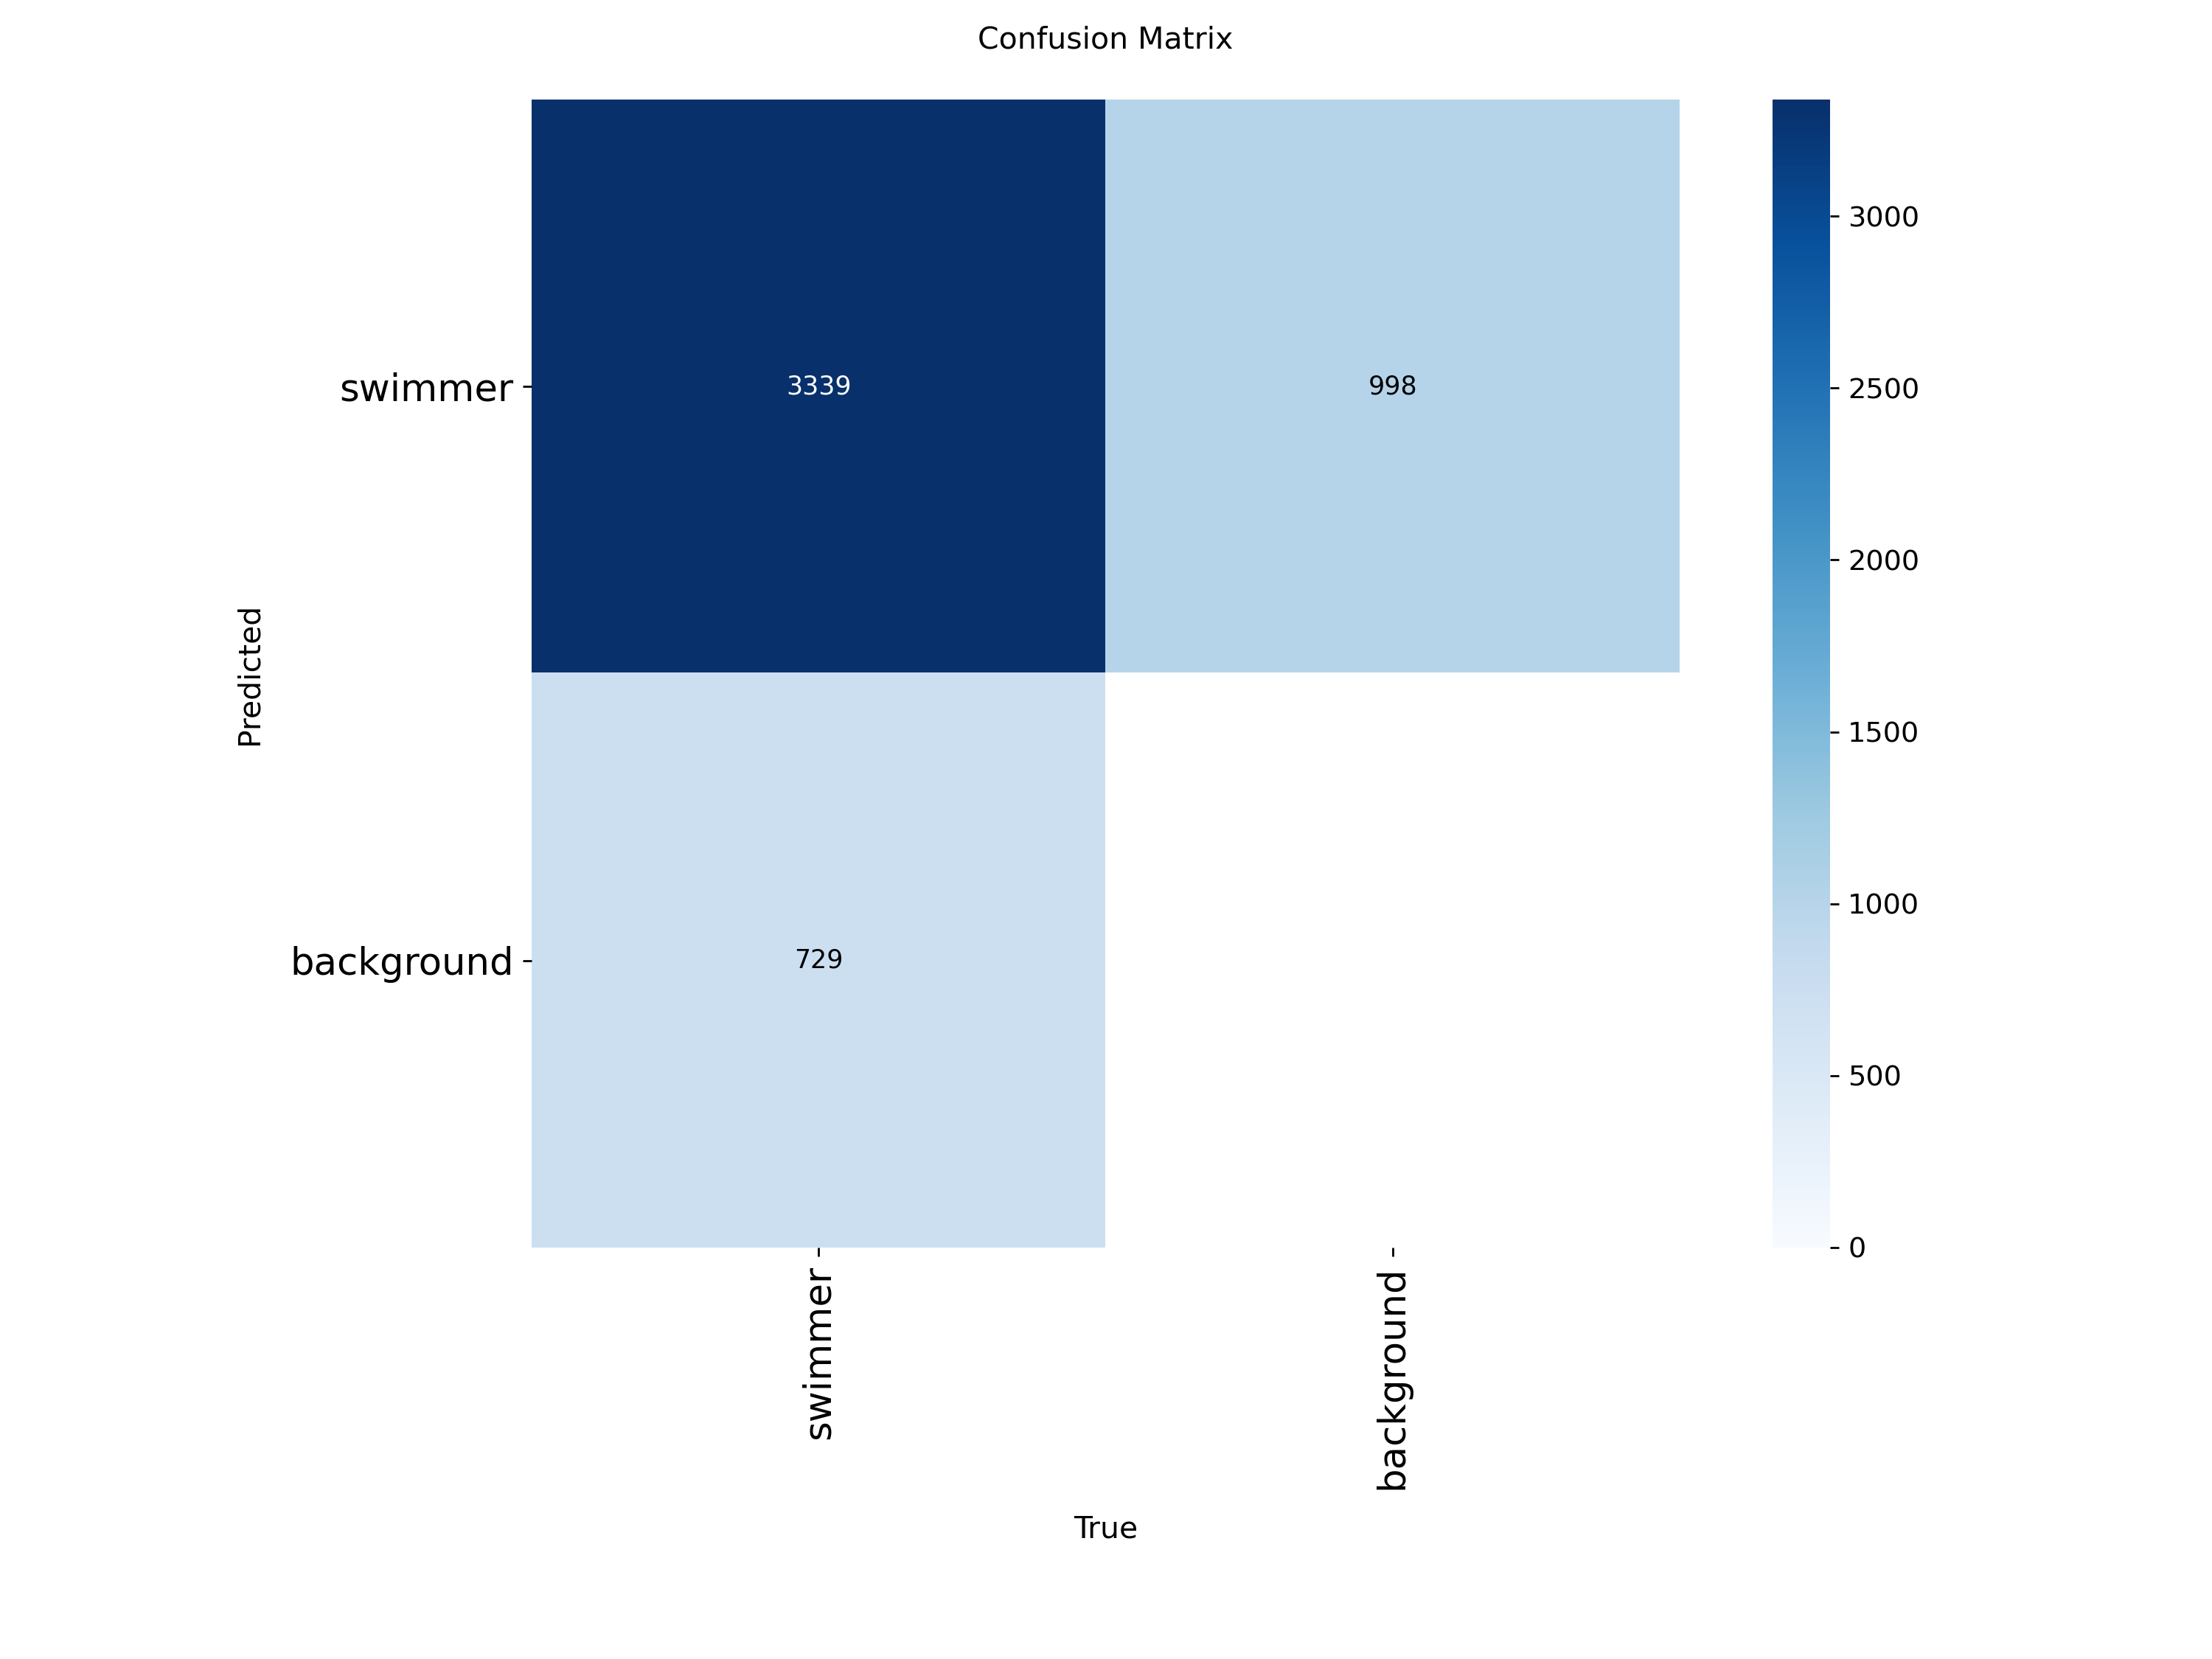

In [ ]:
display(Image(filename=str(metrics.save_dir / 'confusion_matrix.png')))

In [ ]:
test_images = glob.glob('/content/sds_swimmer/test/images/*')

#Select a subset of the test images to predict
subset = random.sample(test_images, min(20, len(test_images)))
print("Selected images:", len(subset))



results = model.predict(
    source=subset,
    conf = 0.25,
    batch = 8,
    show_labels=True,
    show_conf=True,
    save=True
)

Selected images: 20

0: 640x640 (no detections), 8.7ms
1: 640x640 (no detections), 8.7ms
2: 640x640 2 swimmers, 8.7ms
3: 640x640 (no detections), 8.7ms
4: 640x640 (no detections), 8.7ms
5: 640x640 2 swimmers, 8.7ms
6: 640x640 2 swimmers, 8.7ms
7: 640x640 2 swimmers, 8.7ms
8: 640x640 2 swimmers, 8.7ms
9: 640x640 3 swimmers, 8.7ms
10: 640x640 2 swimmers, 8.7ms
11: 640x640 (no detections), 8.7ms
12: 640x640 4 swimmers, 8.7ms
13: 640x640 9 swimmers, 8.7ms
14: 640x640 4 swimmers, 8.7ms
15: 640x640 8 swimmers, 8.7ms
16: 640x640 9 swimmers, 8.7ms
17: 640x640 9 swimmers, 8.7ms
18: 640x640 (no detections), 8.7ms
19: 640x640 2 swimmers, 8.7ms
Speed: 2.1ms preprocess, 8.7ms inference, 0.9ms postprocess per image at shape (8, 3, 640, 640)
Results saved to /content/runs/detect/predict


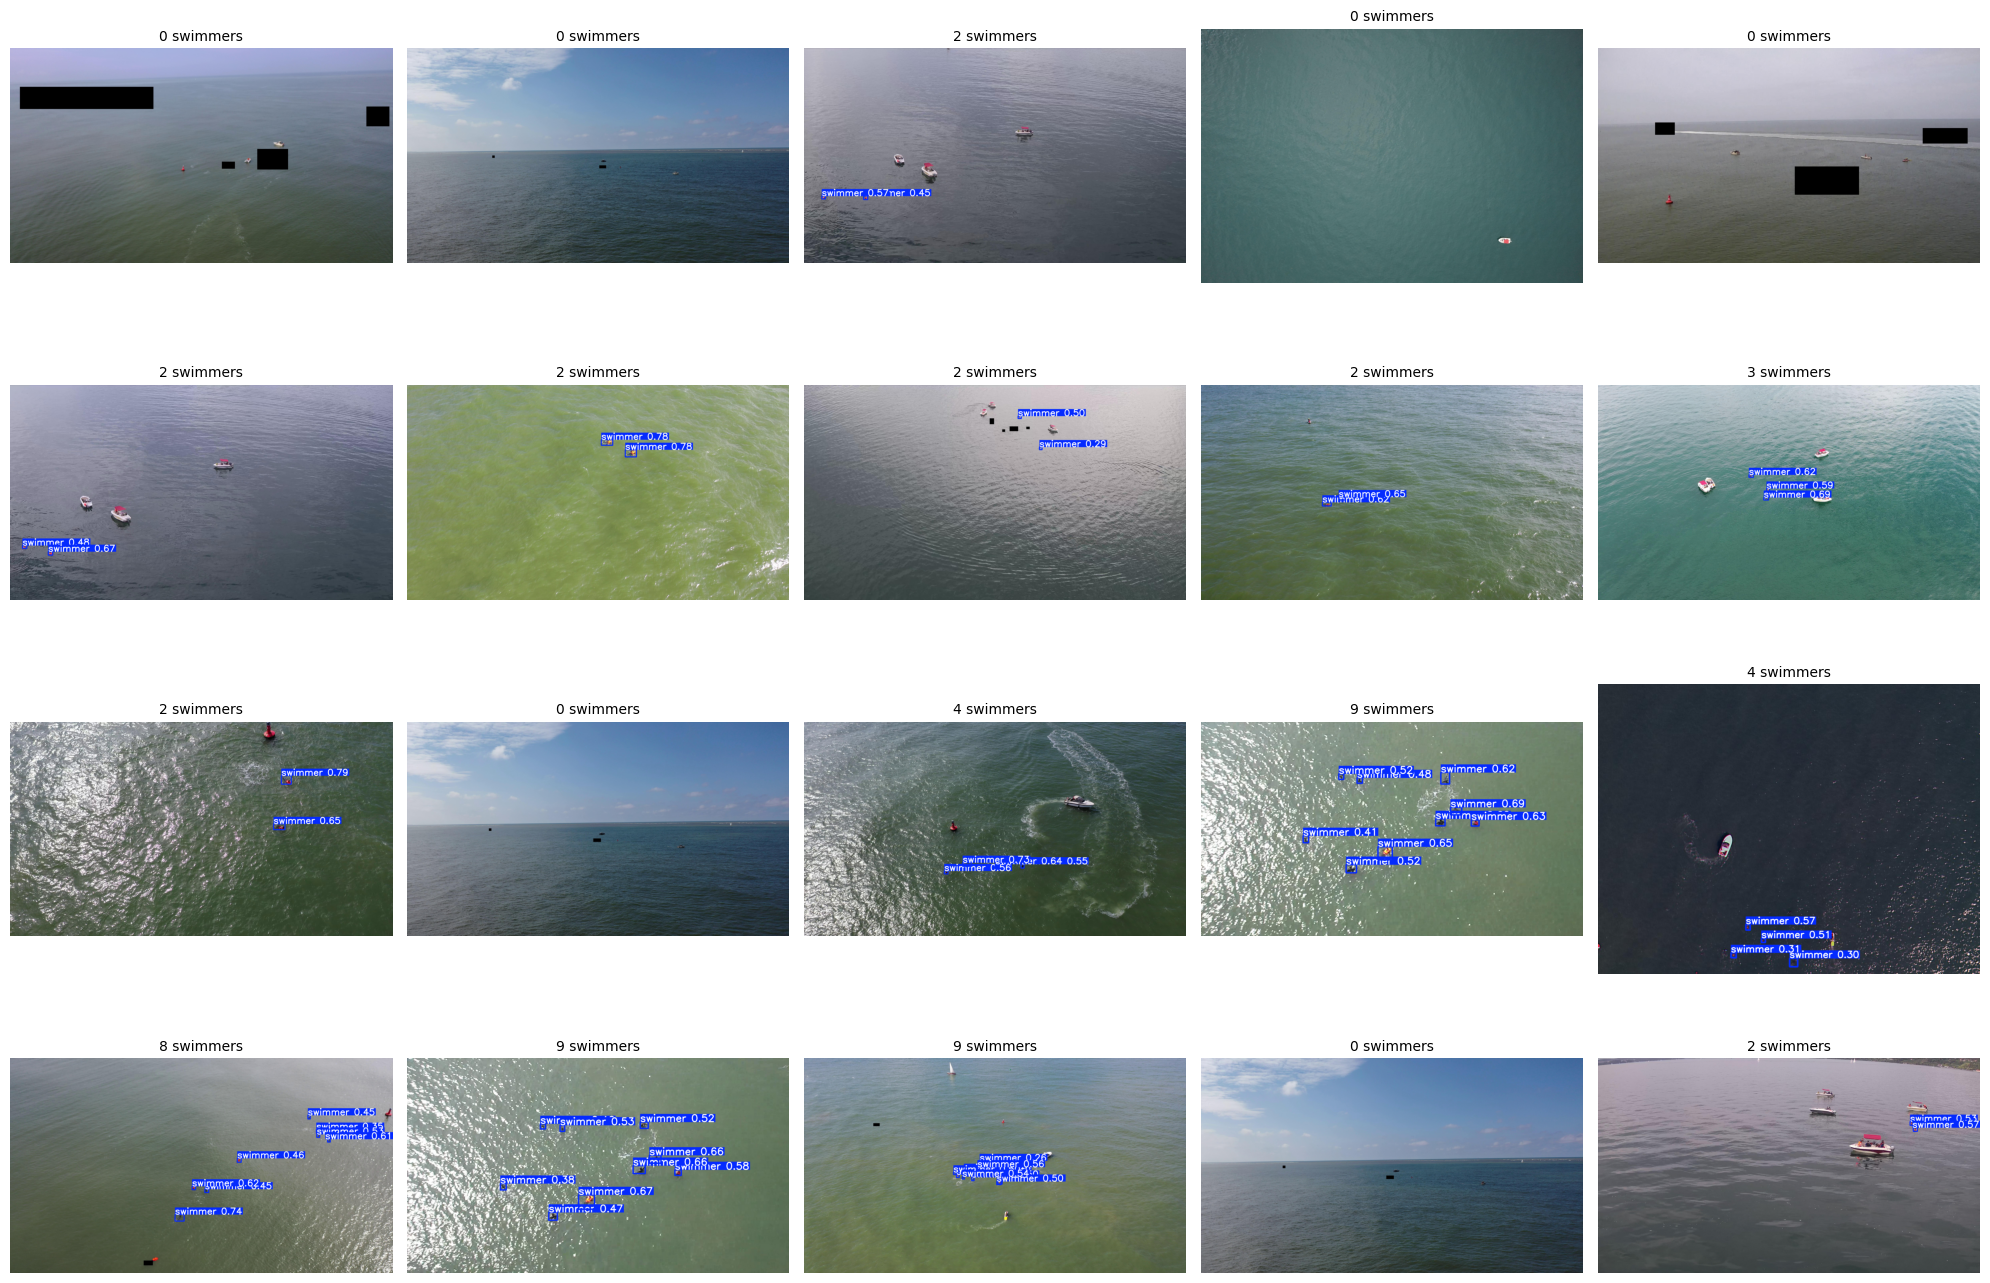

In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(20, 14))
for ax, r in zip(axes.flat, results):
    ax.imshow(r.plot()[:, :, ::-1])   # BGR -> RGB
    ax.set_title(f"{len(r.boxes)} swimmers", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

#YOLOv26 Model Evaluation

In [ ]:
model_v26 = YOLO('/content/yolo26s_final_best.pt')

In [ ]:
metrics_v26 = model_v26.val(
    data = '/content/sds_swimmer/data.yaml',
    split='test',
    imgsz = 800,
    batch=8,
    conf = 0.25
)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3509.1±951.4 MB/s, size: 451.4 KB)
val: Scanning /content/sds_swimmer/test/labels... 1000 images, 225 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1000/1000 2.2Kit/s 0.4s
val: /content/sds_swimmer/test/images/9568.jpg: 1 duplicate labels removed
val: New cache created: /content/sds_swimmer/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 125/125 2.7it/s 46.4s
                   all       1000       4192      0.846      0.829       0.78       0.34
Speed: 1.7ms preprocess, 9.5ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/runs/detect/val-7


In [ ]:
print(f"Final Model Evaluation (YOLOv26)")
print(f"Precision: {metrics_v26.box.mp:.2f}")
print(f"Recall: {metrics_v26.box.mr:.2f}")
print(f"mAP50: {metrics_v26.box.map50:.2f}")
print(f"mAP50-95: {metrics_v26.box.map:.2f}")

Final Model Evaluation (YOLOv26)
Precision: 0.85
Recall: 0.83
mAP50: 0.78
mAP50-95: 0.34


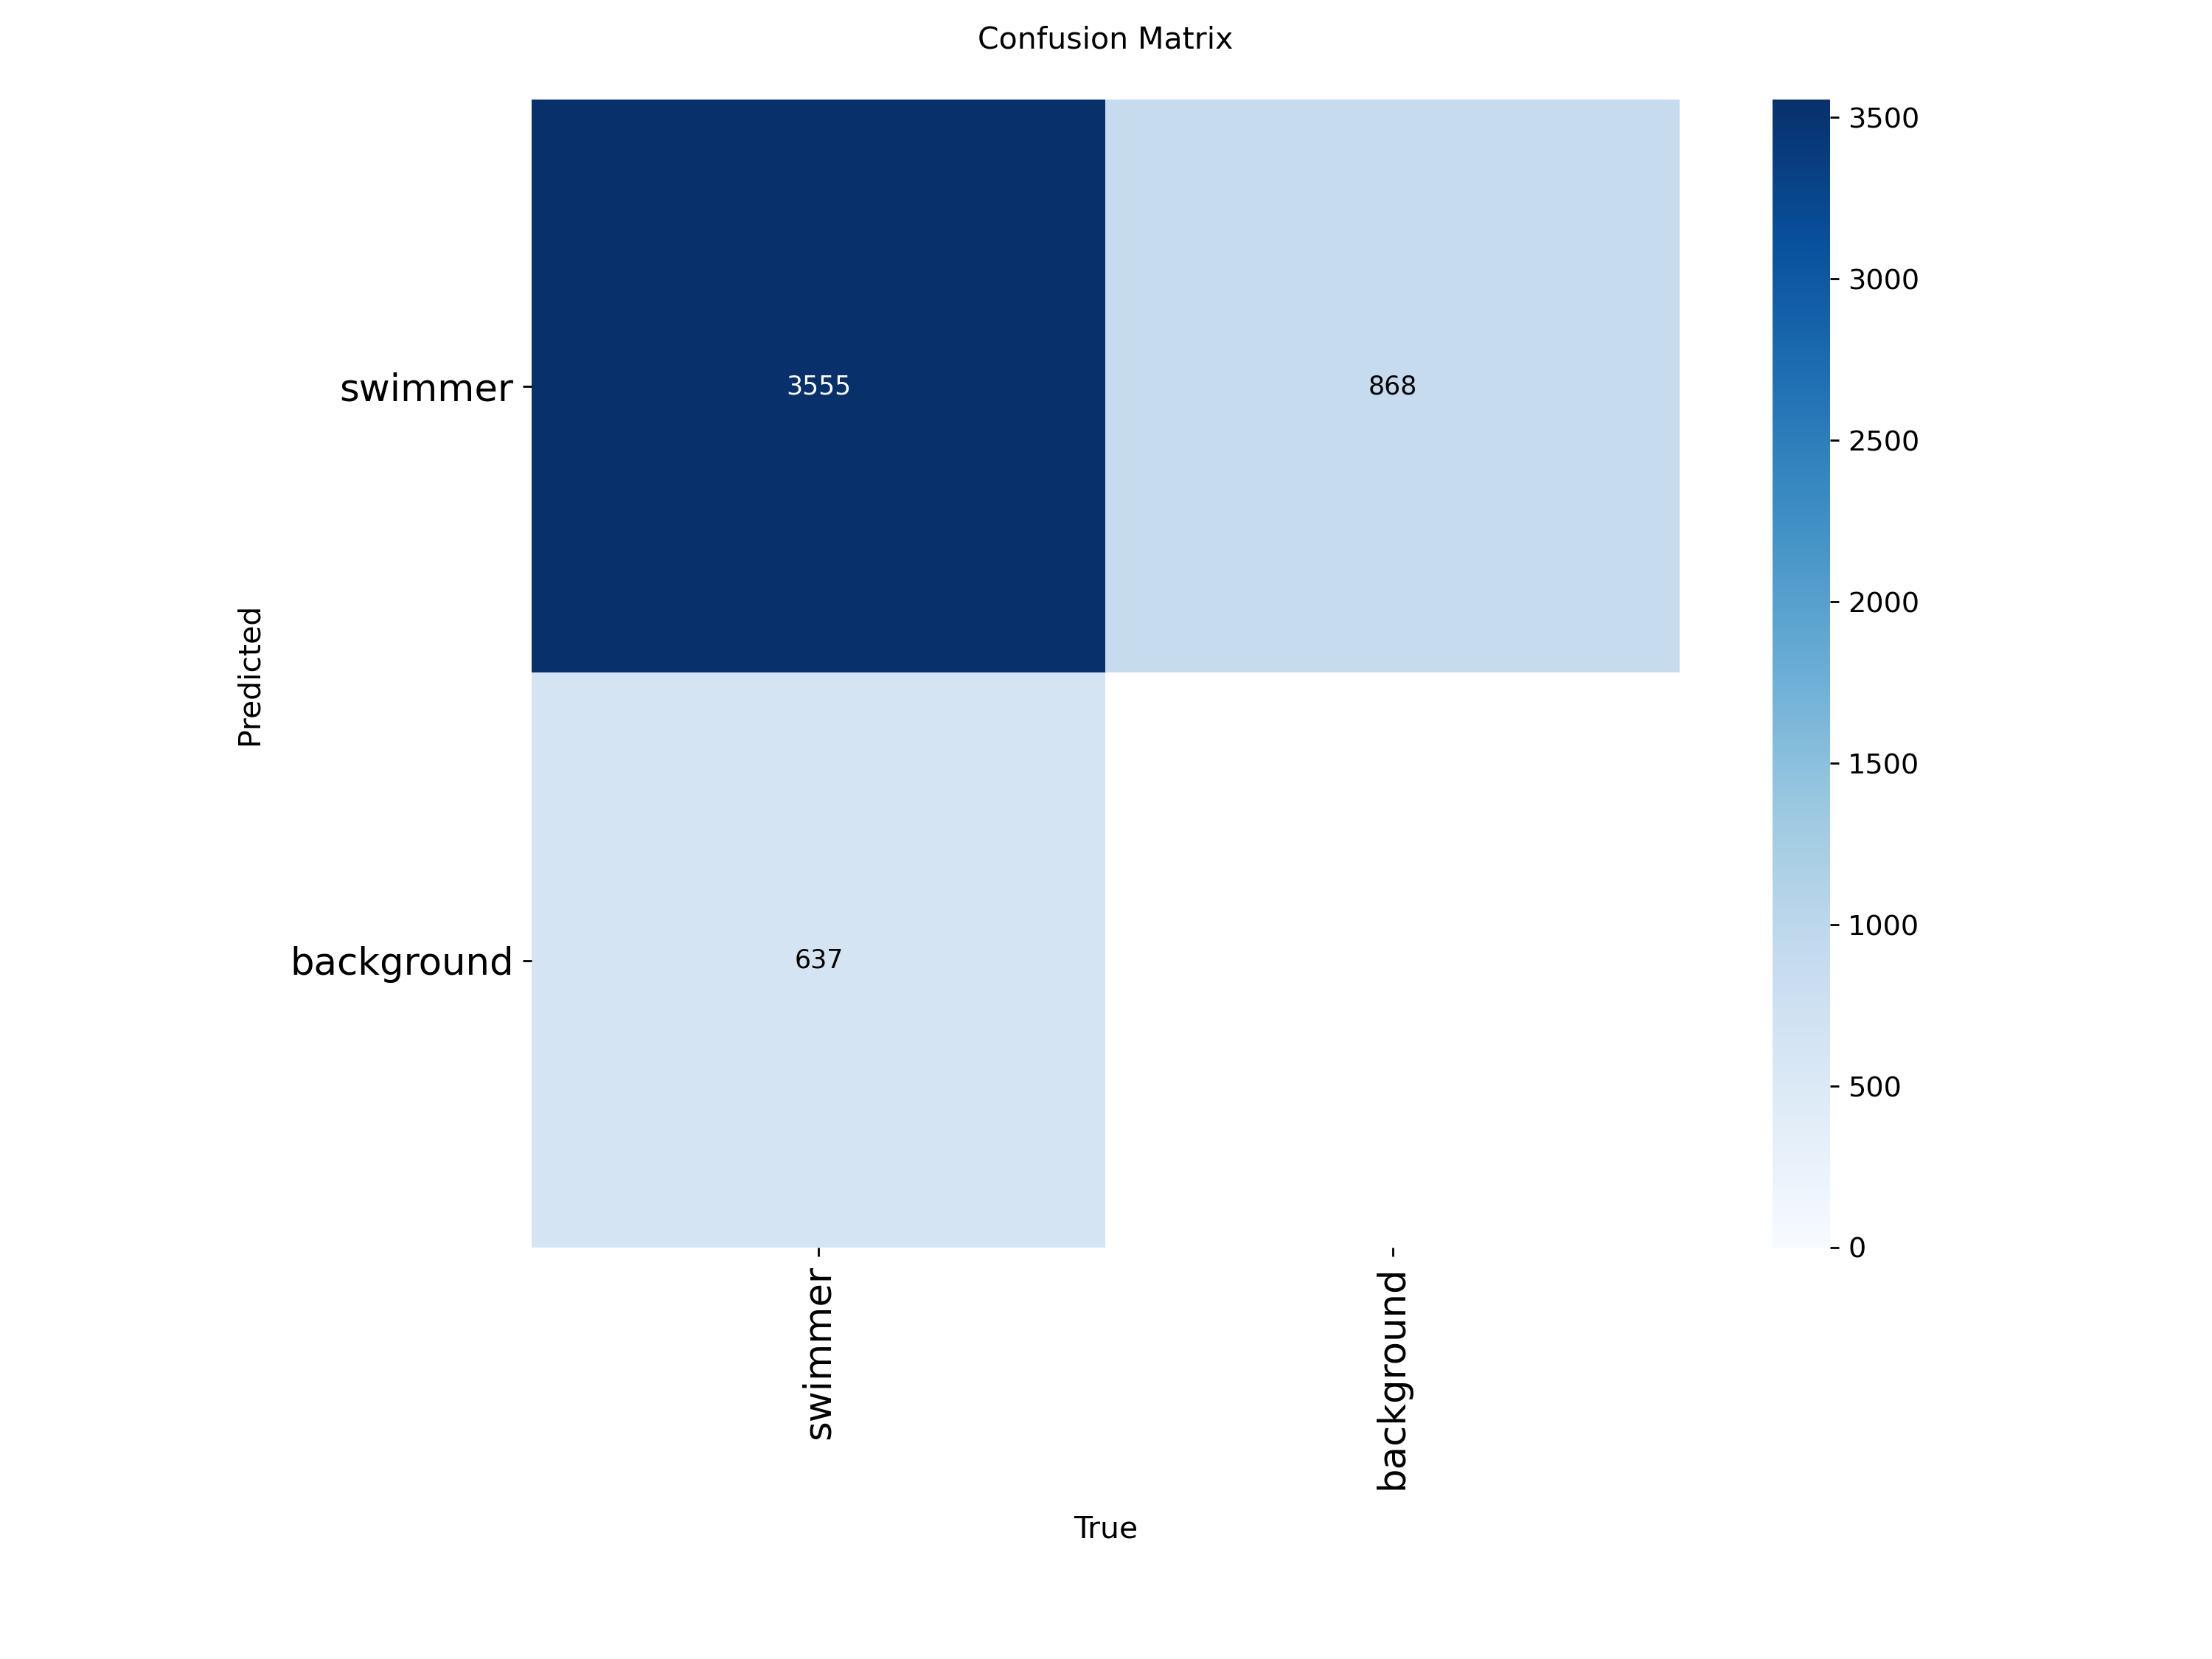

In [ ]:
display(Image(filename=str(metrics_v26.save_dir / 'confusion_matrix.png')))

In [ ]:
results_v26 = model_v26.predict(
    source=subset,
    conf = 0.25,
    batch = 8,
    show_labels=True,
    show_conf=True,
    save=True
)


0: 800x800 (no detections), 14.6ms
1: 800x800 (no detections), 14.6ms
2: 800x800 2 swimmers, 14.6ms
3: 800x800 (no detections), 14.6ms
4: 800x800 (no detections), 14.6ms
5: 800x800 2 swimmers, 14.6ms
6: 800x800 2 swimmers, 14.6ms
7: 800x800 1 swimmer, 14.6ms
8: 800x800 2 swimmers, 14.6ms
9: 800x800 3 swimmers, 14.6ms
10: 800x800 2 swimmers, 14.6ms
11: 800x800 (no detections), 14.6ms
12: 800x800 4 swimmers, 14.6ms
13: 800x800 9 swimmers, 14.6ms
14: 800x800 5 swimmers, 14.6ms
15: 800x800 8 swimmers, 14.6ms
16: 800x800 9 swimmers, 14.6ms
17: 800x800 9 swimmers, 14.6ms
18: 800x800 (no detections), 14.6ms
19: 800x800 2 swimmers, 14.6ms
Speed: 3.0ms preprocess, 14.6ms inference, 0.7ms postprocess per image at shape (8, 3, 800, 800)
Results saved to /content/runs/detect/predict-2


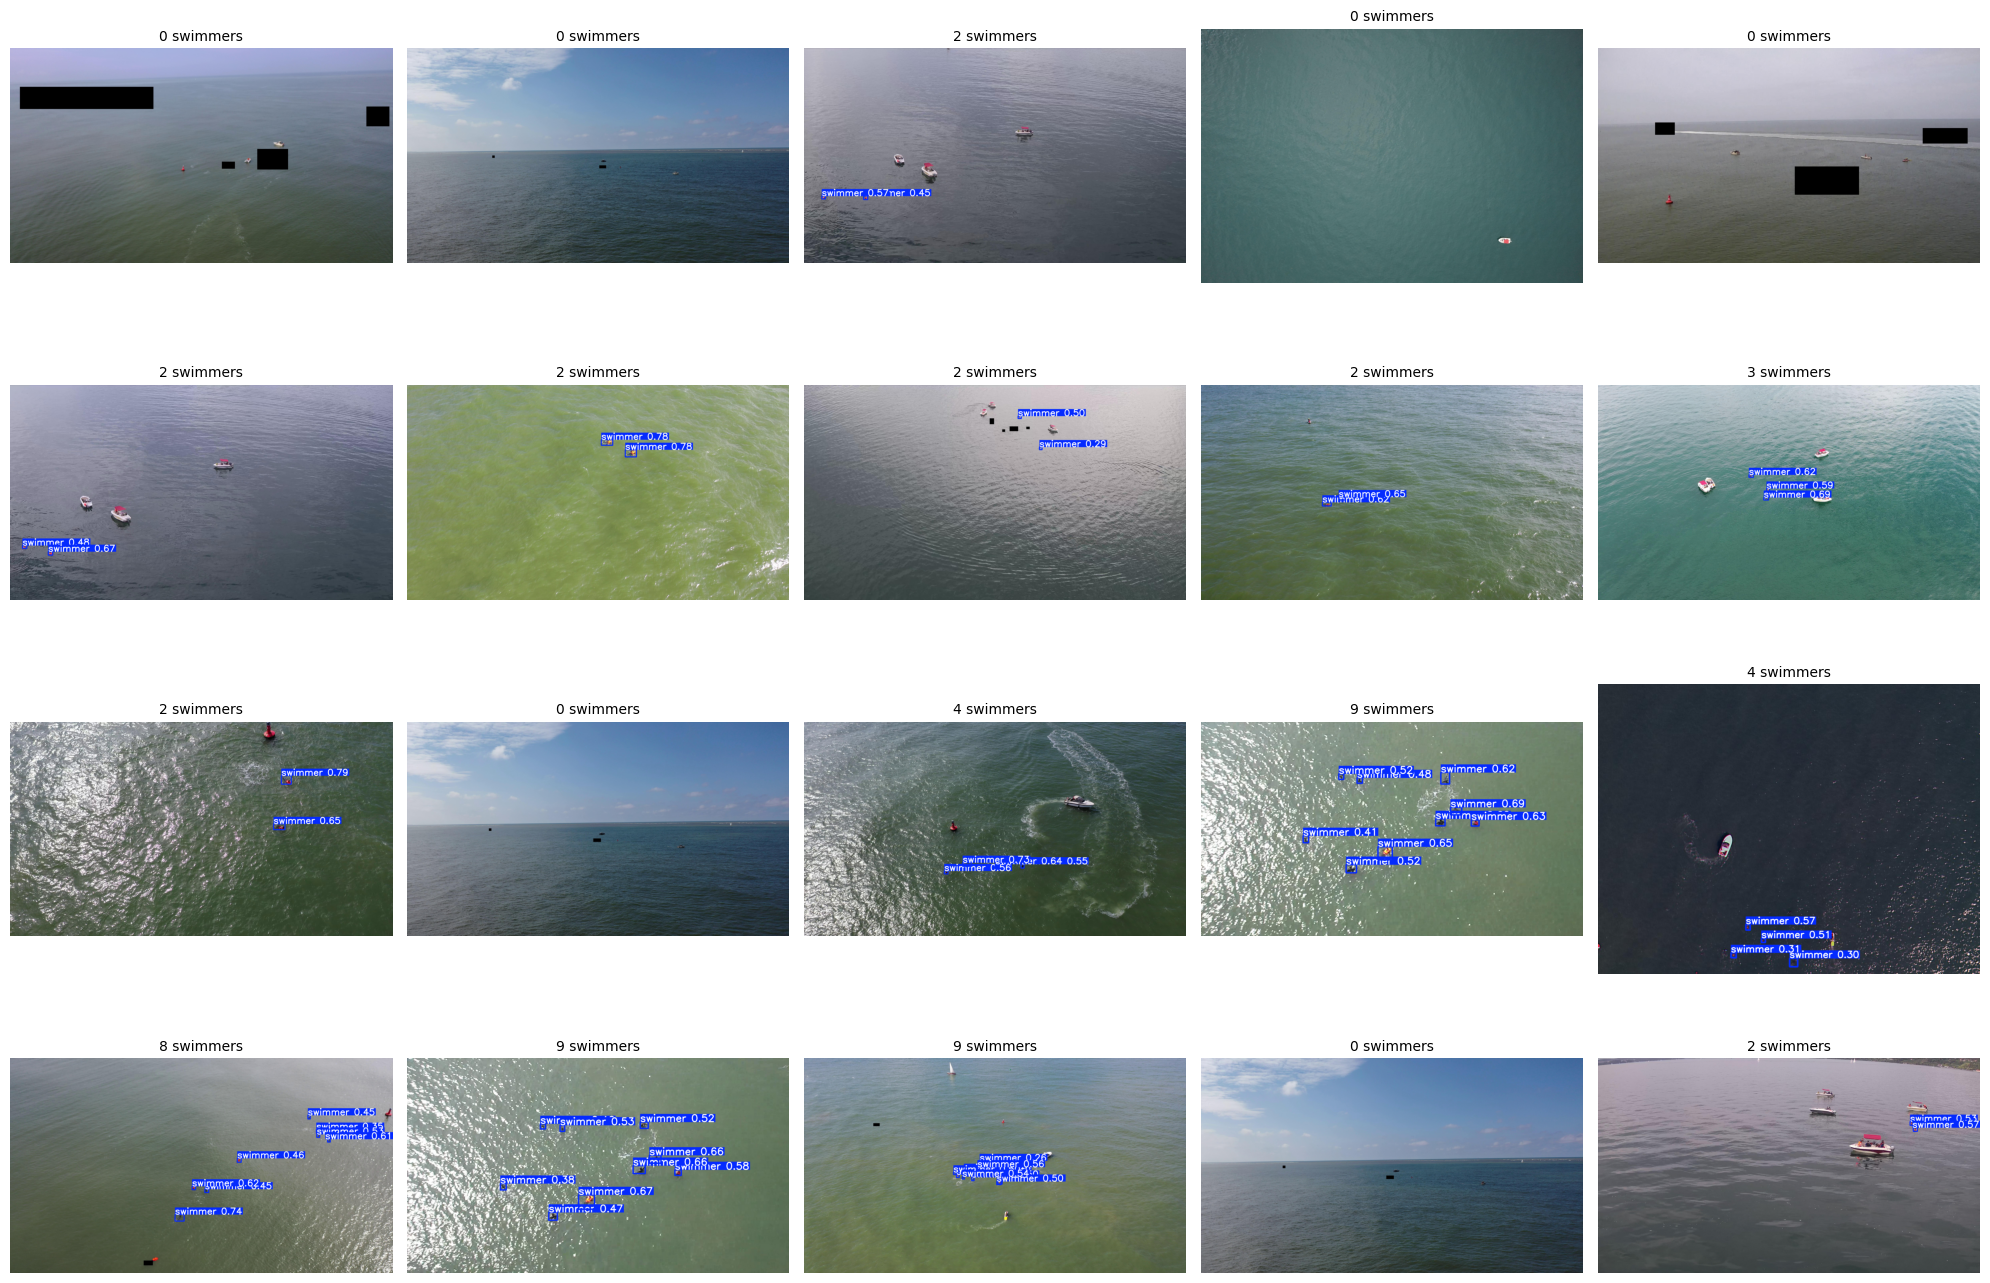

In [ ]:
fig, axes = plt.subplots(4, 5, figsize=(20, 14))
for ax, r in zip(axes.flat, results):
    ax.imshow(r.plot()[:, :, ::-1])
    ax.set_title(f"{len(r.boxes)} swimmers", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()